[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QML_AlzheimerPerformanceSecurity_Luo2024.ipynb)

# QML versus classical ML on the Alzheimer's disease dataset, with simulation cost and attack surface: Luo et al. 2024 step by step

**Paper.** Zhengping Jay Luo, Tyler Stewart, Mourya Narasareddygari, Rui Duan, Shangqing Zhao.
*Quantum Machine Learning: Performance and Security Implications in Real-World Applications.*
Two-page poster, arXiv:2408.04543 (August 2024), DOI 10.48550/arXiv.2408.04543.

**What this notebook does.** The poster trains two classical models (SVM, MLP) and three quantum models (QSVM, a variational
quantum algorithm "VQA", a QCNN) on the public Kaggle *Alzheimer's Disease Dataset* (2,149 patients, 32 features, binary
diagnosis), reports how accuracy grows with the training fraction, which feature matters most, how long the simulated quantum
models take compared with the classical ones, and then argues (without an experiment) that QML inherits adversarial
vulnerabilities and adds new ones (quantum noise). The notebook

1. downloads the same 2,149-patient file from a public Hugging Face mirror and explores it,
2. re-runs the classical learning curve (10 % to 90 % training data) and the feature-influence question,
3. trains QSVM (Qiskit fidelity kernel + SVM), a VQA (variational quantum classifier) and a QCNN in Qiskit on an exact simulator, next to classical models that
   receive exactly the same inputs,
4. measures wall-clock time, CPU time and peak memory, and how the cost of exact simulation grows with the number of qubits,
5. goes one step beyond the poster and turns its two security statements into small experiments: a model-agnostic black-box
   adversarial attack on every model, and a depolarising-noise attack on the trained VQA,
6. ends with a claim-by-claim comparison with the poster's numbers.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo; `FAST_MODE = False` is the
larger run (budgets are in the configuration cell). No GPU, no account and no API key are needed (the data is a public
mirror; the optional Hugging Face token is only forwarded if you have one).

**What you get at the end.** A table that puts every number of the poster next to the notebook's number with a verdict
("reproduced", "not reached", "exceeded", "cannot be checked"), the figures that explain them, and exercises.

**Run record of the committed outputs.** `FAST_MODE = True`, executed top to bottom in one `tools/execute_notebook.py` run (about 19 minutes on a
shared Windows CPU, no GPU). The `FAST_MODE = False` path (QSVM on the full 90 % split, 3 seeds, larger VQA/QCNN budgets) is implemented but was **not** executed
here: its estimated cost on this machine exceeds the 90 minutes allowed for one notebook. Because the committed numbers come from the demo budgets
(small training subsets for the quantum models, 30 attacked patients, 100 noise-evaluated rows), differences of a few accuracy points between models are within
sampling noise; read the verdict table with that in mind.

## The paper in one page

**Problem.** Does quantum machine learning already beat classical machine learning on a real-world, tabular health data set,
what does simulating it cost, and what are the security implications?

**Decision.** Binary classification: will a patient be diagnosed with Alzheimer's disease (`Diagnosis` = 1) or not (0)?

**Methods.** Classical: SVM and MLP (scikit-learn). Quantum (IBM Qiskit): QSVM (Havlicek et al. quantum-kernel SVM), a
variational quantum algorithm (VQA, the quantum analogue of an MLP) and a QCNN (Cong et al.).

**Data.** Kaggle "Alzheimer's Disease Dataset" (R. E. Kharoua, 2024): 2,149 patients, 32 features (demographics, lifestyle,
medical history, clinical measurements, symptoms) plus `PatientID`, `DoctorInCharge` and the label.

**Claims that can be checked (numbers or statements in the poster)**

| # | Claim in the poster | Where |
|---|---|---|
| C1 | SVM/MLP test accuracy grows moderately from about 80 % (10 % of the data for training) to about 87 % (90 %) | Sec. III |
| C2 | The best accuracy of SVM or MLP is 87 %, with 90 % of the data for training | Sec. III |
| C3 | "Memory Complaints" is the most influential of the 32 features | Sec. III |
| C4 | QSVM and the VQA do not surpass their classical counterparts in time or accuracy | Sec. III |
| C5 | The QCNN reaches the same accuracy as the SVM | Sec. III |
| C6 | Training an SVM takes 0.03 s of CPU time, the same-sized simulated QSVM 132.07 s (over 4,000 times longer) | Sec. III |
| C7 | Simulating quantum algorithms on a classical computer needs a very large memory and CPU time | Abstract |
| C8 | QML inherits adversarial-example vulnerability; it is easier to attack when predictions are less accurate (an *inference*, no experiment) | Sec. III |
| C9 | Quantum noise can be exploited to degrade a quantum model (a *discussion*, no experiment) | Sec. III |

C1 to C7 are experiments of the poster. C8 and C9 are arguments; the notebook adds small experiments that test them
(clearly marked as an extension that is not in the poster).

### What follows the paper and what had to be chosen

The poster gives no hyper-parameters, qubit numbers, circuits, split seed or optimiser. Everything unspecified is a choice
and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | Kaggle Alzheimer's Disease Dataset, 2,149 patients, 32 features | Same file (`alzheimers_disease_data.csv`) from the public Hugging Face mirror `Homazu/Alzheimer_Disease_Dataset`; shape and label counts are asserted |
| Dropped columns | not stated | `PatientID` (identifier) and `DoctorInCharge` (one constant value `XXXConfid`) |
| Split | "% of the data for training", 10 % to 90 % | stratified `train_test_split(train_size=f, random_state=seed)`, f = 0.1 ... 0.9, several seeds |
| Classical SVM | scikit-learn SVM, settings not given | `SVC(kernel="rbf", C=1)` after `StandardScaler` (fitted on the training split); linear, unscaled and tuned variants are shown too |
| Classical MLP | scikit-learn MLP, settings not given | `MLPClassifier((64, 32))`, `max_iter=500`, after `StandardScaler` |
| Inputs of the classical models | presumably all 32 features | all 32 features for the claims C1 to C3; the reduced quantum inputs for the like-for-like comparison |
| Quantum inputs | not stated | `SelectKBest(f_classif, k=N_QUBITS)` -> `StandardScaler` -> `MinMaxScaler((0, pi))`, all fitted on the training split, one feature per qubit |
| QSVM | Qiskit quantum kernel `K = abs(<phi(x)|phi(z)>)^2` | `QSVC` + `FidelityStatevectorKernel(zz_feature_map(reps=2, linear))`; kernel bandwidth and `C` tuned on a validation split of the training data |
| VQA | variational circuit, classical optimiser | Qiskit circuit, exact expectation value simulated in batches on Aer (checked against `EstimatorQNN`): `z_feature_map(reps=1)` + `real_amplitudes(reps=2)`, output = mean of the eight `<Z_i>` (exact expectation, no shot noise), squared error, COBYLA; angle scale `bw` tuned on a validation split. A sampler-based Qiskit `VQC` (cross-entropy on 1,024-shot counts) was tried first and did not learn within the CPU budget (accuracy at or below chance), see the critical-reading section |
| QCNN | Cong et al. | Qiskit QCNN tutorial structure (conv + pool layers, 8 qubits), output `<Z>` on the last qubit, squared error, COBYLA (circuit simulated in batches on Aer, checked against `EstimatorQNN`) |
| Simulator | "local computers with simulations" | exact statevector simulation in Qiskit (CPU) |
| Timing | CPU time (SVM 0.03 s, QSVM 132.07 s) | wall-clock and CPU time of `fit` and `predict`, peak resident memory; absolute values depend on the machine |
| Security | discussion only | extension: black-box adversarial attack, depolarising-noise attack (not in the poster) |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a
*session restart* may be requested after the install; if so, restart and run all cells again.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_machine_learning", "qiskit_aer", "huggingface_hub", "psutil", "pylatexenc"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                    "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "huggingface_hub", "psutil"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is a demo (a few minutes of simulation, small training subsets for the
quantum models); `FAST_MODE = False` follows the poster's sizes as far as a CPU simulator allows (the QSVM is trained on the
full 90 % training split, as in the poster's timing statement).

In [2]:
FAST_MODE = True       # True: class demo. False: full run (quantum models see far more data and iterations)
SEED = 42                   # global seed (data checks, tuning split, sampler seeds)
DATA_DIR = "data"           # downloads are cached here
DATA_FILE = ""              # optional: path of your own copy of alzheimers_disease_data.csv (e.g. downloaded from Kaggle and uploaded to Colab)
IBM_TOKEN = ""              # unused: the poster has no real-hardware experiment, everything runs on exact simulators
SHOTS = 1024                # unused by the exact simulators (QSVM kernel, VQA and QCNN use exact statevectors / expectation values)
TOL = 2.0                   # a numeric claim is "reproduced" when within 2 accuracy points
N_QUBITS = 8                # CHOICE: one feature per qubit (8 also suits the 8-qubit QCNN)
TRAIN_FRAC = 0.9            # the poster's best setting: 90 % of the data for training
HF_REPOS = ["Homazu/Alzheimer_Disease_Dataset"]   # public mirror of the Kaggle file (Kharoua 2024)

# paper numbers (poster, Sec. III)
PAPER = dict(acc_10=80.0, acc_90=87.0, best=87.0, svm_cpu_s=0.03, qsvm_cpu_s=132.07, ratio=4000.0)

if FAST_MODE:
    SEEDS_CL = [0, 1, 2]                 # seeds of the classical learning curve
    FRACS = [0.1, 0.3, 0.5, 0.7, 0.9]    # poster: 10 % ... 90 %
    SEEDS_QML = [0]                      # seeds of the QSVM runs
    SEEDS_NN = [0]                       # seeds of the (slower) VQA and QCNN runs
    N_TRAIN_QSVM = 300                   # QSVM training rows (full run: all of the 90 % split)
    N_TUNE_TRAIN, N_TUNE_VAL = 250, 150  # rows used to tune the kernel bandwidth and C
    N_TRAIN_VQA, VQA_ITERS = 100, 220
    N_TUNE_VQA, TUNE_ITERS = 60, 100                        # rows / COBYLA evaluations used to pick the VQA angle scale on a validation split
    N_TRAIN_QCNN, QCNN_ITERS = 100, 300
    N_TEST_QML = 100                     # test rows scored by VQA / QCNN (full run: the whole 10 % test split)
    SCALING_QUBITS = [4, 8, 12, 14, 16]
    ATTACK_N, ATTACK_K, ATTACK_ROUNDS = 30, 12, 2
    NOISE_N_TEST, NOISE_LEVELS = 100, [0.0, 0.01, 0.05, 0.10]
else:
    SEEDS_CL = [0, 1, 2, 3, 4]
    FRACS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    SEEDS_QML = [0, 1, 2]
    SEEDS_NN = [0]
    N_TRAIN_QSVM = None
    N_TUNE_TRAIN, N_TUNE_VAL = 500, 300
    N_TRAIN_VQA, VQA_ITERS = 250, 500
    N_TUNE_VQA, TUNE_ITERS = 120, 200
    N_TRAIN_QCNN, QCNN_ITERS = 250, 800
    N_TEST_QML = None
    SCALING_QUBITS = [4, 8, 12, 14, 16, 18, 20]
    ATTACK_N, ATTACK_K, ATTACK_ROUNDS = 80, 32, 2
    NOISE_N_TEST, NOISE_LEVELS = 215, [0.0, 0.005, 0.01, 0.02, 0.05, 0.10]
EPS_FRACS = [0.05, 0.10, 0.20]         # L-infinity attack budgets as a fraction of the angle range [0, pi]
print("FAST_MODE =", FAST_MODE)

FAST_MODE = True


In [3]:
import os, time, math, threading, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import psutil
warnings.filterwarnings("ignore")
import qiskit, qiskit_aer, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, z_feature_map, real_amplitudes
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from IPython.display import display

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | aer 0.17.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6


### 1.2 Measuring cost: wall-clock time, CPU time and peak memory

The poster's central cost statement is about *time* and *memory* of simulated quantum models. `measure(fn)` runs a function and
returns its result, the wall-clock seconds, the CPU seconds (all threads of this process, `time.process_time`) and the peak
extra resident memory in MB, sampled every 10 ms from a background thread. The numbers depend on the machine (Colab versus
the poster's local computer), so the *ratios* and the *growth with the number of qubits* are what can be compared.

In [4]:
_proc = psutil.Process()
def measure(fn, interval=0.01):
    # run fn(); return (result, wall_seconds, cpu_seconds, peak_extra_rss_MB)
    base = _proc.memory_info().rss; peak = [base]; stop = threading.Event()
    def watch():
        while not stop.is_set():
            peak[0] = max(peak[0], _proc.memory_info().rss); time.sleep(interval)
    th = threading.Thread(target=watch, daemon=True); th.start()
    w0, c0 = time.perf_counter(), time.process_time()
    try:
        out = fn()
    finally:
        wall, cpu = time.perf_counter() - w0, time.process_time() - c0
        stop.set(); th.join()
    peak[0] = max(peak[0], _proc.memory_info().rss)
    return out, wall, cpu, (peak[0] - base) / 2**20

def metrics(y_true, y_pred):
    return dict(acc=100 * accuracy_score(y_true, y_pred), prec=100 * precision_score(y_true, y_pred, zero_division=0),
                rec=100 * recall_score(y_true, y_pred, zero_division=0), f1=100 * f1_score(y_true, y_pred, zero_division=0))

RES = []          # every model run is appended here as one dict
def log(**kw):
    RES.append(kw); return kw
_, w_, c_, m_ = measure(lambda: np.linalg.svd(np.random.default_rng(0).normal(size=(600, 600))))
print(f"measure() self-test: SVD of a 600x600 matrix took {w_:.2f} s wall, {c_:.2f} s CPU, peak extra memory {m_:.1f} MB")

measure() self-test: SVD of a 600x600 matrix took 9.79 s wall, 21.66 s CPU, peak extra memory 24.1 MB


## 2. The data: Kaggle Alzheimer's Disease Dataset

The Kaggle page needs a login, so the notebook uses a public Hugging Face copy of the same file
(`alzheimers_disease_data.csv`). Gated datasets would need your own Hugging Face token in Colab *Secrets* (name `HF_TOKEN`);
this mirror is public, so the token is only forwarded if you have one. You can also upload the Kaggle file yourself and set
`DATA_FILE`. The cell checks that the file really is the 2,149-patient table of the poster.

In [5]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# The mirror used here is public: the token is only passed on if the reader has one (no gated data).

def load_alzheimer():
    if DATA_FILE and os.path.exists(DATA_FILE):
        return pd.read_csv(DATA_FILE), "user file " + DATA_FILE
    path = os.path.join(DATA_DIR, "alzheimers_disease_data.csv")
    if os.path.exists(path):
        return pd.read_csv(path), "cache " + path
    from huggingface_hub import hf_hub_download
    last = None
    for repo in HF_REPOS:
        try:
            p = hf_hub_download(repo, "alzheimers_disease_data.csv", repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
            return pd.read_csv(p), "Hugging Face " + repo
        except Exception as e:
            last = e; print("download failed:", repo, repr(e)[:120])
    raise RuntimeError("could not download the data; download alzheimers_disease_data.csv from "
                       "https://www.kaggle.com/dsv/8668279 , upload it and set DATA_FILE. Last error: " + repr(last))

raw, source = load_alzheimer()
ID_COLS, LABEL = ["PatientID", "DoctorInCharge"], "Diagnosis"
FEATURES = [c for c in raw.columns if c not in ID_COLS + [LABEL]]
X_all = raw[FEATURES].astype(float).values
y_all = raw[LABEL].astype(int).values
assert raw.shape == (2149, 35) and len(FEATURES) == 32, raw.shape                  # poster: 2,149 patients, 32 features
assert raw.isna().sum().sum() == 0 and not raw.duplicated().any()
print("source:", source, "| table shape:", raw.shape, "| model features:", len(FEATURES))

source: cache data\alzheimers_disease_data.csv | table shape: (2149, 35) | model features: 32


## Dataset Exploration and Visualisation

Everything below is the real table, nothing is simulated. The label has only two original values (0 = no Alzheimer's
diagnosis, 1 = diagnosis); the file has no multi-class attack/disease labels, so the colouring is binary. The first plot is
the class distribution, then a table of all features, then two scatter plots of real patients coloured by their true label:
the raw PCA coordinates (PCA fitted on the training split only, all 32 features standardised) and the angles that the
quantum circuits receive (the two strongest of the `N_QUBITS` selected features after the [0, pi] scaling).

In [6]:
print("shape:", raw.shape, "(rows = patients, columns = identifier + 32 features + label + DoctorInCharge)")
print("feature names:", FEATURES)
print("original label column 'Diagnosis' values / counts:", raw[LABEL].value_counts().sort_index().to_dict(),
      "-> 0 = no Alzheimer's diagnosis, 1 = Alzheimer's diagnosis")
print("DoctorInCharge distinct values:", raw["DoctorInCharge"].unique().tolist(), "(constant: dropped)")
desc = raw[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)
desc["distinct"] = raw[FEATURES].nunique()
desc["corr with label"] = [np.corrcoef(raw[c], y_all)[0, 1] for c in FEATURES]
display(desc.round(3))

shape: (2149, 35) (rows = patients, columns = identifier + 32 features + label + DoctorInCharge)
feature names: ['Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']
original label column 'Diagnosis' values / counts: {0: 1389, 1: 760} -> 0 = no Alzheimer's diagnosis, 1 = Alzheimer's diagnosis
DoctorInCharge distinct values: ['XXXConfid'] (constant: dropped)


,mean,std,min,max,distinct,corr with label
Age,74.91,8.99,60.00,90.00,31,-0.005
Gender,0.51,0.50,0.00,1.00,2,-0.021
Ethnicity,0.70,1.00,0.00,3.00,4,-0.015
EducationLevel,1.29,0.90,0.00,3.00,4,-0.044
BMI,27.66,7.22,15.01,39.99,2149,0.026
Smoking,0.29,0.45,0.00,1.00,2,-0.005
AlcoholConsumption,10.04,5.76,0.00,19.99,2149,-0.008
PhysicalActivity,4.92,2.86,0.00,9.99,2149,0.006
DietQuality,4.99,2.91,0.01,10.00,2149,0.009
SleepQuality,7.05,1.76,4.00,10.00,2149,-0.057


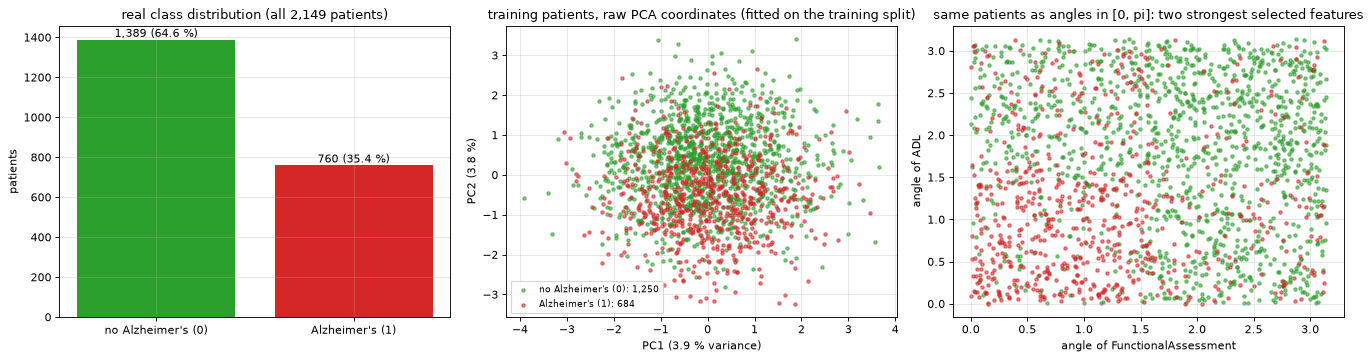

features selected for the quantum circuits on this split (one per qubit): ['EducationLevel', 'SleepQuality', 'CholesterolHDL', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL']
training split 1,934 patients, test split 215 patients; Alzheimer's share train 35.4 %, test 35.3 %


In [7]:
tr0, te0 = train_test_split(np.arange(len(y_all)), train_size=TRAIN_FRAC, stratify=y_all, random_state=SEED)
sc0 = StandardScaler().fit(X_all[tr0]); pca0 = PCA(n_components=2, random_state=SEED).fit(sc0.transform(X_all[tr0]))
P0 = pca0.transform(sc0.transform(X_all[tr0]))
sel0 = SelectKBest(f_classif, k=N_QUBITS).fit(X_all[tr0], y_all[tr0])
A0 = sel0.transform(X_all[tr0]); ss0 = StandardScaler().fit(A0); mm0 = MinMaxScaler((0, np.pi)).fit(ss0.transform(A0))
Z0 = mm0.transform(ss0.transform(A0))
sel_names0 = [f for f, m in zip(FEATURES, sel0.get_support()) if m]
order0 = np.argsort(-sel0.scores_[sel0.get_support()])           # the two strongest selected features
LAB = {0: "no Alzheimer's (0)", 1: "Alzheimer's (1)"}; COL = {0: "tab:green", 1: "tab:red"}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
cnt = np.bincount(y_all)
ax[0].bar([LAB[0], LAB[1]], cnt, color=[COL[0], COL[1]]); ax[0].set_ylabel("patients"); ax[0].set_title("real class distribution (all 2,149 patients)")
for k, v in enumerate(cnt): ax[0].text(k, v, f"{v:,} ({100 * v / cnt.sum():.1f} %)", ha="center", va="bottom")
for c in (0, 1):
    m = y_all[tr0] == c
    ax[1].scatter(P0[m, 0], P0[m, 1], s=9, alpha=0.6, color=COL[c], label=f"{LAB[c]}: {m.sum():,}")
    ax[2].scatter(Z0[m, order0[0]], Z0[m, order0[1]], s=9, alpha=0.6, color=COL[c])
ax[1].set_title("training patients, raw PCA coordinates (fitted on the training split)")
ax[1].set_xlabel(f"PC1 ({100 * pca0.explained_variance_ratio_[0]:.1f} % variance)"); ax[1].set_ylabel(f"PC2 ({100 * pca0.explained_variance_ratio_[1]:.1f} %)"); ax[1].legend(fontsize=8)
ax[2].set_title("same patients as angles in [0, pi]: two strongest selected features")
ax[2].set_xlabel("angle of " + sel_names0[order0[0]]); ax[2].set_ylabel("angle of " + sel_names0[order0[1]])
plt.tight_layout(); plt.show()
print("features selected for the quantum circuits on this split (one per qubit):", sel_names0)
print(f"training split {len(tr0):,} patients, test split {len(te0):,} patients; Alzheimer's share train {100 * y_all[tr0].mean():.1f} %, test {100 * y_all[te0].mean():.1f} %")

**What the plots show.** The classes are imbalanced (about 65 % negative, 35 % positive), so a constant "no Alzheimer's"
predictor scores about 64.6 %. In the two leading PCA directions the classes overlap heavily: the diagnosis depends on a few
clinical scores (functional assessment, ADL, MMSE, memory complaints) that are diluted among many lifestyle and laboratory
features that carry almost no signal in this data set. In the angle plot the two strongest selected features already
separate a good part of the classes, which is why a handful of qubits can work here.

## 3. Classical models: learning curve and feature influence (claims C1 to C3)

The poster trains SVM and MLP on 10 % to 90 % of the patients and tests on the rest. Every transform (`StandardScaler`) is fitted on
the training split only. All 32 features are used, as the poster talks about "32 features". We add a RandomForest as a
reference and repeat each point over several split seeds (mean +- std).

model,"MLP (64,32)",RandomForest (200),"SVM (rbf, C=1)"
train fraction,,,
0.1,79.17,85.13,78.50
0.3,80.47,90.48,82.86
0.5,80.81,91.72,83.38
0.7,79.48,93.28,83.26
0.9,80.31,93.64,83.72


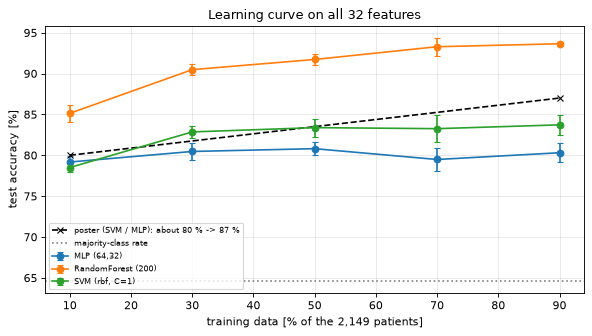

(95 s)


In [8]:
def classical_models(seed):
    return {"SVM (rbf, C=1)": SVC(kernel="rbf", C=1.0, random_state=seed),                              # CHOICE: sklearn defaults, the poster gives none
            "MLP (64,32)": MLPClassifier((64, 32), max_iter=500, random_state=seed),                    # CHOICE
            "RandomForest (200)": RandomForestClassifier(200, random_state=seed, n_jobs=2)}             # extra reference, not in the poster

def make_split(seed, frac=TRAIN_FRAC):
    return train_test_split(np.arange(len(y_all)), train_size=frac, stratify=y_all, random_state=seed)

t0 = time.time(); rows = []
for frac in FRACS:
    for s in SEEDS_CL:
        tr, te = make_split(s, frac)
        sc = StandardScaler().fit(X_all[tr]); A, B = sc.transform(X_all[tr]), sc.transform(X_all[te])
        for name, m in classical_models(s).items():
            m.fit(A, y_all[tr]); rows.append(dict(model=name, frac=frac, seed=s, acc=100 * accuracy_score(y_all[te], m.predict(B))))
LC = pd.DataFrame(rows)
tab = LC.groupby(["model", "frac"]).acc.agg(["mean", "std"]).unstack(0)
display(tab["mean"].round(2).rename_axis("train fraction"))
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for name, g in LC.groupby("model"):
    s_ = g.groupby("frac").acc.agg(["mean", "std"]); ax.errorbar(s_.index * 100, s_["mean"], yerr=s_["std"], marker="o", capsize=3, label=name)
ax.plot([10, 90], [PAPER["acc_10"], PAPER["acc_90"]], "k--x", label="poster (SVM / MLP): about 80 % -> 87 %")
ax.axhline(100 * (1 - y_all.mean()), color="gray", ls=":", label="majority-class rate")
ax.set_xlabel("training data [% of the 2,149 patients]"); ax.set_ylabel("test accuracy [%]"); ax.set_title("Learning curve on all 32 features"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s)")

In [9]:
# Claim C1/C2: what do the SVM and MLP reach at 10 % and 90 %?  And could a differently configured SVM reach the poster's 87 %?
LC_m = LC.groupby(["model", "frac"]).acc.mean()
for name in ["SVM (rbf, C=1)", "MLP (64,32)"]:
    print(f"{name:16s}: 10 % -> {LC_m[(name, 0.1)]:.1f} %   90 % -> {LC_m[(name, 0.9)]:.1f} %   (poster: about 80 % -> 87 %)")

# Variants of the SVM at 90 % training data (poster does not say how its SVM was configured). The tuned one selects C, gamma and kernel by 3-fold CV on the TRAINING split only.
rows = []
for s in SEEDS_CL:
    tr, te = make_split(s, 0.9); Xa, Xb, ya, yb = X_all[tr], X_all[te], y_all[tr], y_all[te]
    sc = StandardScaler().fit(Xa); A, B = sc.transform(Xa), sc.transform(Xb)
    v = {"rbf, scaled": SVC(), "rbf, unscaled": None, "linear, scaled": SVC(kernel="linear"), "logistic regression": LogisticRegression(max_iter=2000)}
    for name, m in v.items():
        if name == "rbf, unscaled":
            rows.append(dict(variant=name, seed=s, acc=100 * SVC().fit(Xa, ya).score(Xb, yb)))
        else:
            rows.append(dict(variant=name, seed=s, acc=100 * m.fit(A, ya).score(B, yb)))
    gs = GridSearchCV(SVC(), [{"kernel": ["rbf"], "C": [0.3, 1, 3, 10], "gamma": ["scale", 0.01]}, {"kernel": ["linear"], "C": [0.1, 1]}], cv=3, n_jobs=1).fit(A, ya)
    rows.append(dict(variant="tuned (CV on train only)", seed=s, acc=100 * gs.score(B, yb)))
SVMV = pd.DataFrame(rows).groupby("variant").acc.agg(["mean", "std"]).round(2)
display(SVMV)
BEST_SVM_MLP = max(LC_m[("SVM (rbf, C=1)", 0.9)], LC_m[("MLP (64,32)", 0.9)], SVMV.loc[["linear, scaled", "tuned (CV on train only)"], "mean"].max())
print(f"best SVM/MLP accuracy at 90 % training data in this notebook: {BEST_SVM_MLP:.2f} %  (poster: 87 %)")
print("(the maximum over several SVM variants and the MLP, compared on the test split: an optimistic upper bound, like a poster that reports its best accuracy; the CV-tuned SVM is the leakage-free one)")

SVM (rbf, C=1)  : 10 % -> 78.5 %   90 % -> 83.7 %   (poster: about 80 % -> 87 %)
MLP (64,32)     : 10 % -> 79.2 %   90 % -> 80.3 %   (poster: about 80 % -> 87 %)


,mean,std
variant,,
"linear, scaled",85.89,1.17
logistic regression,85.89,1.42
"rbf, scaled",83.72,1.23
"rbf, unscaled",64.65,0.00
tuned (CV on train only),84.50,0.27


best SVM/MLP accuracy at 90 % training data in this notebook: 85.89 %  (poster: 87 %)
(the maximum over several SVM variants and the MLP, compared on the test split: an optimistic upper bound, like a poster that reports its best accuracy; the CV-tuned SVM is the leakage-free one)


### 3.1 Which feature matters most? (claim C3)

The poster says "Memory Complaints" is the most influential factor. It does not say how influence was measured, so four
common measures are computed on the 90 % training split: the ANOVA F-score, the absolute correlation with the label, the
RandomForest impurity importance and the permutation importance of the SVM on the held-out 10 %. The question is where
`MemoryComplaints` ranks in each.

,ANOVA F,|corr|,RF impurity,SVM permutation
FunctionalAssessment,291.524,0.362,0.181,0.104
ADL,236.703,0.330,0.162,0.081
MemoryComplaints,200.489,0.307,0.081,0.076
MMSE,116.097,0.238,0.122,0.073
BehavioralProblems,100.578,0.222,0.050,0.071
SleepQuality,6.809,0.059,0.029,0.004
CholesterolHDL,5.044,0.051,0.031,-0.001
EducationLevel,3.811,0.044,0.011,0.000


rank of MemoryComplaints (1 = most influential): {'ANOVA F': 3, '|corr|': 3, 'RF impurity': 4, 'SVM permutation': 3}
most influential feature by measure: {'ANOVA F': 'FunctionalAssessment', '|corr|': 'FunctionalAssessment', 'RF impurity': 'FunctionalAssessment', 'SVM permutation': 'FunctionalAssessment'}


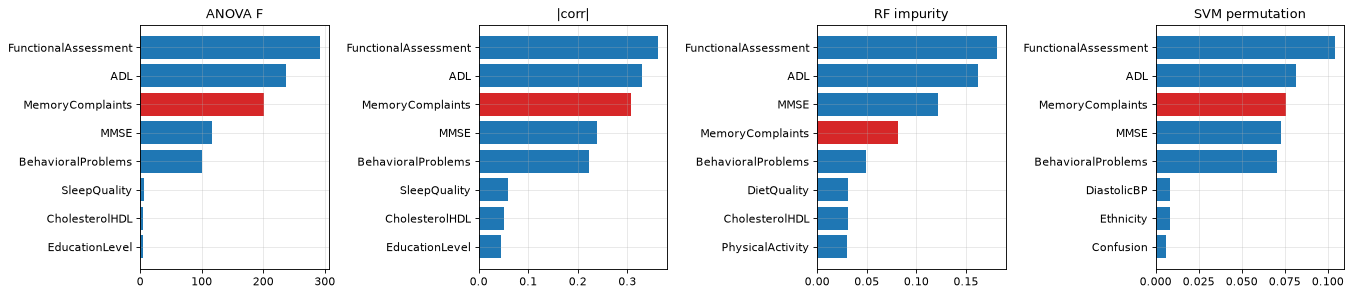

In [10]:
tr, te = make_split(SEED, 0.9); sc = StandardScaler().fit(X_all[tr]); A, B = sc.transform(X_all[tr]), sc.transform(X_all[te])
F, _ = f_classif(X_all[tr], y_all[tr])
corr = np.array([abs(np.corrcoef(X_all[tr][:, j], y_all[tr])[0, 1]) for j in range(len(FEATURES))])
rf = RandomForestClassifier(300, random_state=SEED, n_jobs=2).fit(A, y_all[tr])
svm_ = SVC().fit(A, y_all[tr]); pi = permutation_importance(svm_, B, y_all[te], n_repeats=10, random_state=SEED, n_jobs=1)
IMP = pd.DataFrame({"ANOVA F": F, "|corr|": corr, "RF impurity": rf.feature_importances_, "SVM permutation": pi.importances_mean}, index=FEATURES)
RANK = IMP.rank(ascending=False).astype(int)
display(IMP.sort_values("ANOVA F", ascending=False).head(8).round(3))
print("rank of MemoryComplaints (1 = most influential):", RANK.loc["MemoryComplaints"].to_dict())
print("most influential feature by measure:", {c: IMP[c].idxmax() for c in IMP})
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, c in zip(ax, IMP):
    s_ = IMP[c].sort_values().tail(8); a.barh(s_.index, s_.values, color=["tab:red" if i == "MemoryComplaints" else "tab:blue" for i in s_.index]); a.set_title(c)
plt.tight_layout(); plt.show()

## 4. Preprocessing for the quantum models

A circuit can only receive a handful of numbers, so the 32 features are reduced to `N_QUBITS = 8` (one feature per qubit; the
poster does not say how). The reduction is fitted on the training rows only: `SelectKBest(f_classif)` -> `StandardScaler` ->
`MinMaxScaler((0, pi))`; test angles are clipped to [0, pi]. The classical SVM, MLP and RandomForest are also trained on exactly
these 8 angles, so the quantum and classical models compare like with like.

For the quantum **kernel** the angle range matters a lot: the product of 8 rotations with angles up to pi gives a kernel matrix
that is close to the identity (every patient looks different from every other), so the SVM cannot generalise. A *bandwidth*
`bw` multiplies the angles before they enter the feature map (`bw * angles`); it is tuned on a validation split of the training
data only (CHOICE, section 6).

In [11]:
def prep_q(tr, te, k=N_QUBITS):
    # SelectKBest -> StandardScaler -> MinMax(0, pi), everything fitted on the training rows; test angles clipped to [0, pi]
    sel = SelectKBest(f_classif, k=k).fit(X_all[tr], y_all[tr])
    ss = StandardScaler().fit(sel.transform(X_all[tr])); mm = MinMaxScaler((0, np.pi)).fit(ss.transform(sel.transform(X_all[tr])))
    f = lambda idx: np.clip(mm.transform(ss.transform(sel.transform(X_all[idx]))), 0, np.pi)
    return f(tr), f(te), [n for n, m in zip(FEATURES, sel.get_support()) if m]

def stratified_subset(idx, n, seed):
    # CHOICE: class-proportional random subset of size n of the index array idx (None = all)
    if n is None or n >= len(idx):
        return np.asarray(idx)
    return np.asarray(train_test_split(idx, train_size=n, stratify=y_all[idx], random_state=seed)[0])

def classical_on(Ztr, ytr, Zte, seed):
    out = {}
    for name, m in {"SVM": SVC(random_state=seed), "MLP": MLPClassifier((64, 32), max_iter=500, random_state=seed),
                    "RandomForest": RandomForestClassifier(200, random_state=seed, n_jobs=2)}.items():
        fit_, wf, cf, mf = measure(lambda: m.fit(Ztr, ytr)); p, wp, cp, _ = measure(lambda: m.predict(Zte))
        out[name] = dict(pred=p, t_fit=wf, cpu_fit=cf, mem_fit=mf, t_pred=wp, model=m)
    return out

Ztr_demo, Zte_demo, names_demo = prep_q(*make_split(0))
print("selected features:", names_demo)
print("angle ranges on the training split:", np.round(Ztr_demo.min(0), 2), "..", np.round(Ztr_demo.max(0), 2))

selected features: ['SleepQuality', 'CardiovascularDisease', 'CholesterolHDL', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL']
angle ranges on the training split: [0. 0. 0. 0. 0. 0. 0. 0.] .. [3.14 3.14 3.14 3.14 3.14 3.14 3.14 3.14]


## Quantum Circuit Architecture

This section draws the circuits that the notebook really trains and evaluates. They are built once here by the same factory
functions that the training sections call, and the training sections assert that the model they fit has the same gate counts,
depth and parameter count as the drawing. Three distinct architectures:

1. **QSVM kernel circuit**: `zz_feature_map(8, reps=2, entanglement="linear")` â€” Hadamards, data-dependent phase gates and
   `ZZ` interactions between neighbouring qubits. The kernel entry for two patients is `abs(<0|U(z)^dagger U(x)|0>)^2`; it is
   computed exactly from statevectors (no measurement, no trainable parameters; the 8 parameters are the 8 data angles).
2. **VQA** (variational quantum classifier): the Z (product) feature map (1 repetition) followed by a trainable `real_amplitudes(8, reps=2)` ansatz;
   the output is the mean of the eight single-qubit expectation values `<Z_i>` (exact, in [-1, 1]; positive = "Alzheimer's"). The angles are multiplied by a scale `bw` tuned on validation data.
3. **QCNN**: `z_feature_map(8)` angle encoding, three convolution + pooling stages (8 -> 4 -> 2 -> 1 qubit) following the Qiskit
   QCNN tutorial, and the expectation value of `Z` on the last surviving qubit as the output (an `EstimatorQNN`).

Assumptions: the poster does not give any circuit; qubit count, feature maps, ansatz depth and the QCNN block structure are
choices (`# CHOICE:`).

VQA: batched Aer expectation == EstimatorQNN forward pass on 6 random rows (max diff 4.2e-16)  ->  OK


QCNN: batched Aer expectation == EstimatorQNN forward pass on 6 random rows (max diff 6.2e-16)  ->  OK
1. QSVM kernel circuit: 8-qubit ZZFeatureMap, 2 reps, linear entanglement (state |phi(x)>; the kernel is |<phi(x)|phi(z)>|^2)
  qubits: 8 | depth (elementary gates): 31 | parameters: 8 (trainable: 0) | gates: {'p': 30, 'cx': 28, 'h': 16}


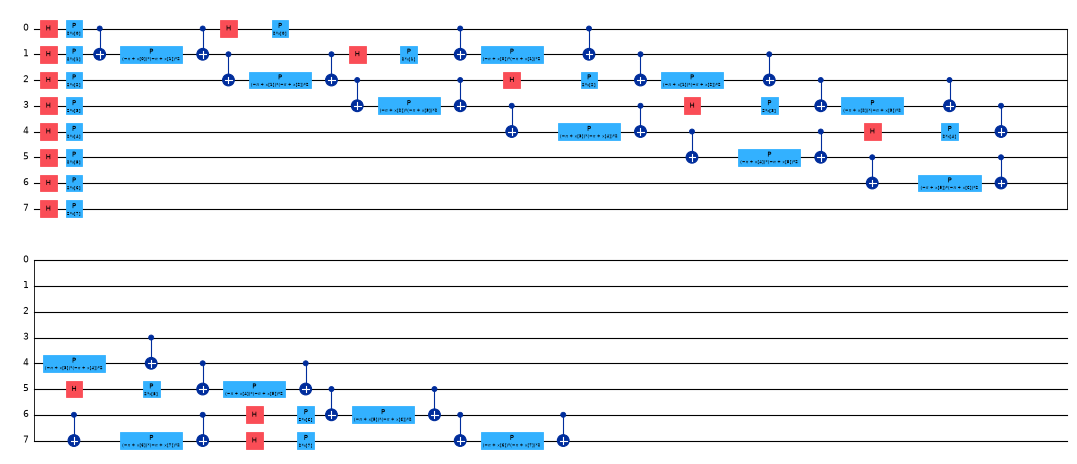

2. VQA circuit: ZFeatureMap(1 rep) + RealAmplitudes(2 reps); output = mean of <Z_i>
  qubits: 8 | depth (elementary gates): 14 | parameters: 32 (trainable: 24) | gates: {'ry': 24, 'cx': 14, 'h': 8, 'p': 8}


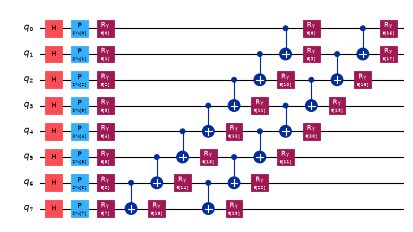

3. QCNN circuit: ZFeatureMap + 3 x (convolution, pooling); output = <Z> on the last qubit
  qubits: 8 | depth (elementary gates): 135 | parameters: 71 (trainable: 63) | gates: {'rz': 56, 'cx': 56, 'ry': 42, 'barrier': 21, 'h': 8, 'p': 8}


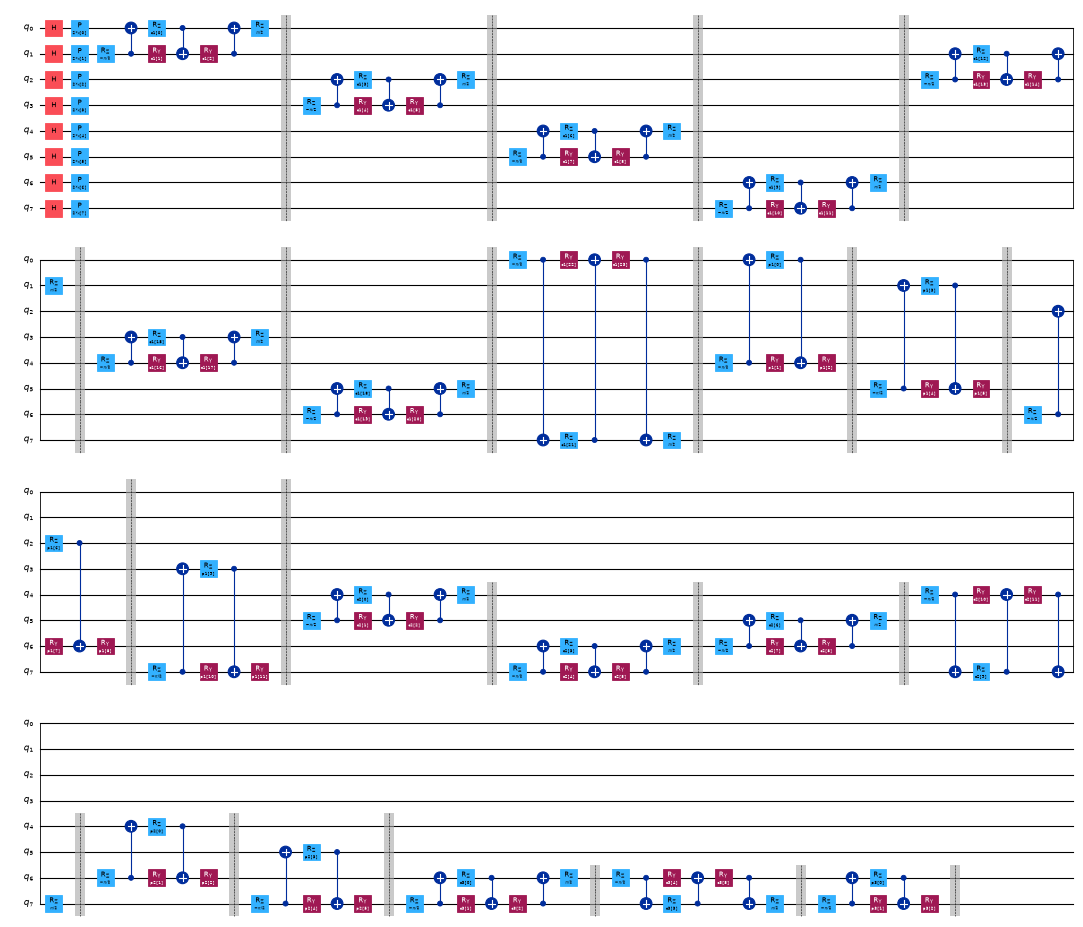

,circuit,qubits,depth,parameters,trainable
0,"1. QSVM kernel circuit: 8-qubit ZZFeatureMap, ...",8,31,8,0
1,2. VQA circuit: ZFeatureMap(1 rep) + RealAmpli...,8,14,32,24
2,3. QCNN circuit: ZFeatureMap + 3 x (convolutio...,8,135,71,63


In [12]:
# ---- circuit factories (used by the drawing AND by the training sections) ----
def make_qsvm_fm():
    return zz_feature_map(N_QUBITS, reps=2, entanglement="linear")                              # CHOICE: ZZ map, 2 repetitions, linear entanglement

VQA_FM = "Z"                                                                                # CHOICE: feature map of the variational classifier
def make_vqa_circuit():
    fm = zz_feature_map(N_QUBITS, reps=1, entanglement="linear") if VQA_FM == "ZZ" else z_feature_map(N_QUBITS, reps=1)    # CHOICE
    an = real_amplitudes(N_QUBITS, reps=2)                                                      # CHOICE: 24 trainable rotations
    qc = QuantumCircuit(N_QUBITS); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)
    return qc, fm, an
VQA_OBS = SparsePauliOp.from_list([("I" * i + "Z" + "I" * (N_QUBITS - 1 - i), 1 / N_QUBITS) for i in range(N_QUBITS)])       # CHOICE: mean of the Z_i, so that every qubit (feature) reaches the output

def conv_circuit(p):
    t = QuantumCircuit(2); t.rz(-np.pi / 2, 1); t.cx(1, 0); t.rz(p[0], 0); t.ry(p[1], 1); t.cx(0, 1); t.ry(p[2], 1); t.cx(1, 0); t.rz(np.pi / 2, 0); return t
def pool_circuit(p):
    t = QuantumCircuit(2); t.rz(-np.pi / 2, 1); t.cx(1, 0); t.rz(p[0], 0); t.ry(p[1], 1); t.cx(0, 1); t.ry(p[2], 1); return t
def conv_layer(nq, prefix):
    qc, qs, ps, i = QuantumCircuit(nq, name="conv"), list(range(nq)), ParameterVector(prefix, nq * 3), 0
    for a, b in zip(qs[0::2], qs[1::2]):
        qc.compose(conv_circuit(ps[i:i + 3]), [a, b], inplace=True); qc.barrier(); i += 3
    for a, b in zip(qs[1::2], qs[2::2] + [0]):
        qc.compose(conv_circuit(ps[i:i + 3]), [a, b], inplace=True); qc.barrier(); i += 3
    return qc
def pool_layer(src, snk, prefix):
    qc, ps = QuantumCircuit(len(src) + len(snk), name="pool"), ParameterVector(prefix, 3 * len(src))
    for k, (a, b) in enumerate(zip(src, snk)):
        qc.compose(pool_circuit(ps[3 * k:3 * k + 3]), [a, b], inplace=True); qc.barrier()
    return qc
def make_qcnn_ansatz():
    a = QuantumCircuit(8)                                                                          # CHOICE: Qiskit QCNN tutorial structure for 8 qubits
    a.compose(conv_layer(8, "c1"), list(range(8)), inplace=True); a.compose(pool_layer([0, 1, 2, 3], [4, 5, 6, 7], "p1"), list(range(8)), inplace=True)
    a.compose(conv_layer(4, "c2"), list(range(4, 8)), inplace=True); a.compose(pool_layer([0, 1], [2, 3], "p2"), list(range(4, 8)), inplace=True)
    a.compose(conv_layer(2, "c3"), list(range(6, 8)), inplace=True); a.compose(pool_layer([0], [1], "p3"), list(range(6, 8)), inplace=True)
    return a
QCNN_OBS = SparsePauliOp.from_list([("Z" + "I" * 7, 1)])                                           # Z on qubit 7, the qubit that survives the last pooling
def make_qcnn_circuit():
    fm, an = z_feature_map(8, reps=1), make_qcnn_ansatz(); qc = QuantumCircuit(8); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)
    return qc, fm, an

class BatchedExpval:
    # Exact <observable> of a parameterised circuit for many rows at once. The circuit is the one drawn below; Aer evaluates all rows of a
    # batch in one call (the EstimatorQNN of Qiskit-Machine-Learning simulates them one by one, which is several times slower on a CPU).
    def __init__(self, circuit, input_params, weight_params, observable, simulator=None, basis_gates=None):
        self.sim = simulator or AerSimulator(method="statevector")
        qc = circuit.copy()
        if basis_gates is not None:                                    # noisy simulation: first rewrite the circuit in the gates the noise model knows
            qc = transpile(qc, basis_gates=basis_gates, optimization_level=1, seed_transpiler=SEED)
        qc.save_expectation_value(observable, list(range(qc.num_qubits)), label="e")
        self.qc = transpile(qc, self.sim, optimization_level=0)
        self.inp, self.wt = {p.name: j for j, p in enumerate(input_params)}, {p.name: j for j, p in enumerate(weight_params)}
    def __call__(self, Z, w):
        Z, w = np.asarray(Z, dtype=float), np.asarray(w, dtype=float)
        binds = {p: (Z[:, self.inp[p.name]] if p.name in self.inp else np.full(len(Z), w[self.wt[p.name]])).tolist() for p in self.qc.parameters}
        res = self.sim.run(self.qc, parameter_binds=[binds]).result()
        return np.array([res.data(i)["e"] for i in range(len(Z))], dtype=float)

class VariationalClassifier:
    # f(x; w) = <O> in [-1, 1]; class 1 when f > 0. Trained with scipy COBYLA on the mean squared error to the targets -1 / +1
    # (the QNN-classifier recipe of Qiskit).
    def __init__(self, circuit, input_params, weight_params, observable, seed, maxiter, name, bw=1.0):
        self.f = BatchedExpval(circuit, input_params, weight_params, observable); self.n_w = len(weight_params); self.bw = bw     # bw: the circuit receives bw x angles
        self.seed, self.maxiter, self.name, self.hist, self.weights = seed, maxiter, name, [], None
        self.circuit, self.input_params, self.weight_params = circuit, list(input_params), list(weight_params)
    def fit(self, Z, y):
        t = 2 * np.asarray(y) - 1; self.hist = []
        def loss(w):
            v = float(np.mean((self.f(self.bw * Z, w) - t) ** 2)); self.hist.append(v); return v
        res = minimize(loss, np.random.default_rng(self.seed).random(self.n_w), method="COBYLA", options={"maxiter": self.maxiter})   # CHOICE: random start in [0, 1)
        self.weights = res.x; return self
    def decision_function(self, Z): return self.f(self.bw * np.asarray(Z), self.weights)
    def predict(self, Z): return (self.decision_function(Z) > 0).astype(int)

def make_vqa(seed, maxiter=None, bw=1.0):
    qc, fm, an = make_vqa_circuit(); return VariationalClassifier(qc, fm.parameters, an.parameters, VQA_OBS, seed, maxiter or VQA_ITERS, "VQA", bw)
def make_qcnn(seed, maxiter=None):
    qc, fm, an = make_qcnn_circuit(); return VariationalClassifier(qc, fm.parameters, an.parameters, QCNN_OBS, seed, maxiter or QCNN_ITERS, "QCNN")

# the batched simulator gives the same numbers as Qiskit-Machine-Learning's EstimatorQNN (the reference implementation of these two models)
for nm_, (qc_, fm_, an_), ob_ in [("VQA", make_vqa_circuit(), VQA_OBS), ("QCNN", make_qcnn_circuit(), QCNN_OBS)]:
    Zc = np.random.default_rng(1).uniform(0, np.pi, (6, 8)); wc = np.random.default_rng(2).uniform(0, 2 * np.pi, len(an_.parameters))
    ref = EstimatorQNN(circuit=qc_, observables=ob_, input_params=fm_.parameters, weight_params=an_.parameters).forward(Zc, wc)[:, 0]
    mine = BatchedExpval(qc_, fm_.parameters, an_.parameters, ob_)(Zc, wc); assert np.allclose(ref, mine, atol=1e-8), (nm_, ref, mine)
    print(f"{nm_}: batched Aer expectation == EstimatorQNN forward pass on 6 random rows (max diff {np.abs(ref - mine).max():.1e})  ->  OK")

BASIS = ["h", "p", "rz", "ry", "rx", "cx", "x"]
ARCH = []
def show(qc, title, trainable, fold=40, scale=0.5):
    dec = transpile(qc, basis_gates=BASIS, optimization_level=0)                                   # composite blocks written out as elementary gates
    print(f"{title}\n  qubits: {qc.num_qubits} | depth (elementary gates): {dec.depth()} | parameters: {qc.num_parameters} (trainable: {trainable}) | gates: {dict(dec.count_ops())}")
    display(dec.draw("mpl", fold=fold, scale=scale)); plt.close("all")
    ARCH.append(dict(circuit=title, qubits=qc.num_qubits, depth=dec.depth(), parameters=qc.num_parameters, trainable=trainable, ops=dict(dec.count_ops())))
    return dec

DRAWN = {}
DRAWN["qsvm"] = show(make_qsvm_fm(), "1. QSVM kernel circuit: 8-qubit ZZFeatureMap, 2 reps, linear entanglement (state |phi(x)>; the kernel is |<phi(x)|phi(z)>|^2)", 0)
_qv, _fv, _av = make_vqa_circuit()
DRAWN["vqa"] = show(_qv, "2. VQA circuit: ZFeatureMap(1 rep) + RealAmplitudes(2 reps); output = mean of <Z_i>", _av.num_parameters)
_qc, _fm, _an = make_qcnn_circuit()
DRAWN["qcnn"] = show(_qc, "3. QCNN circuit: ZFeatureMap + 3 x (convolution, pooling); output = <Z> on the last qubit", _an.num_parameters)
display(pd.DataFrame(ARCH).drop(columns="ops"))

## 5. QSVM: quantum kernel + support vector machine

A QSVM maps each patient `x` to a quantum state `|phi(x)>` with the ZZ feature map and uses the kernel
`K(x, z) = abs(<phi(x)|phi(z)>)^2` in an ordinary SVM. With 8 qubits the exact kernel needs the full state vectors (256
amplitudes) of all training patients and `n_train^2 / 2` inner products, which is where the simulation cost of the poster's
132 s comes from.

### 5.1 Kernel bandwidth and C (tuned on a validation split of the training rows only)

seed 0: best bandwidth 0.0312 (x angles in [0, pi]), C = 10, validation accuracy 83.3 % | classical RBF SVM on the same validation rows: 79.3 %


C,1,10,100
bw,,,
0.015625,75.3,80.7,81.3
0.031250,80.7,83.3,80.7
0.062500,80.7,82.0,80.7
0.125000,82.7,83.3,83.3
0.250000,74.7,74.7,74.7
0.500000,68.0,68.7,68.7
1.000000,66.0,64.7,64.7


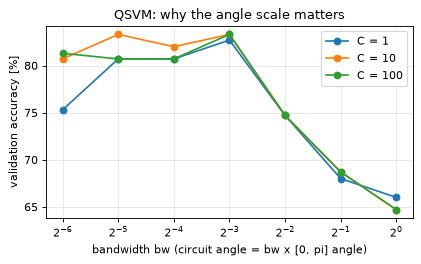

(111 s)


In [13]:
BW_GRID = [1 / 64, 1 / 32, 1 / 16, 1 / 8, 1 / 4, 1 / 2, 1.0]; C_GRID = [1, 10, 100]       # CHOICE: bandwidth multiplies the [0, pi] angles before the feature map

def tune_bw(seed):
    tr, _ = make_split(seed)
    a, b = train_test_split(tr, train_size=0.7, stratify=y_all[tr], random_state=seed)
    a, b = stratified_subset(a, N_TUNE_TRAIN, seed), stratified_subset(b, N_TUNE_VAL, seed)       # validation rows are never test rows
    Za, Zb, _ = prep_q(a, b); kern = FidelityStatevectorKernel(feature_map=make_qsvm_fm()); rows = []
    for bw in BW_GRID:
        Kaa, Kba = kern.evaluate(bw * Za), kern.evaluate(bw * Zb, bw * Za)
        for C in C_GRID:
            rows.append(dict(bw=bw, C=C, val_acc=100 * SVC(kernel="precomputed", C=C).fit(Kaa, y_all[a]).score(Kba, y_all[b])))
    # reference: classical RBF SVM on the same validation split and the same angles
    ref = 100 * SVC().fit(Za, y_all[a]).score(Zb, y_all[b])
    return pd.DataFrame(rows), ref

t0 = time.time(); TUNE = {}
for s in SEEDS_QML:
    TUNE[s], ref = tune_bw(s); best = TUNE[s].sort_values(["val_acc", "bw"], ascending=[False, True]).iloc[0]
    print(f"seed {s}: best bandwidth {best.bw:.4f} (x angles in [0, pi]), C = {best.C:g}, validation accuracy {best.val_acc:.1f} % | classical RBF SVM on the same validation rows: {ref:.1f} %")
piv = TUNE[SEEDS_QML[0]].pivot(index="bw", columns="C", values="val_acc").round(1); display(piv)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for C in C_GRID: ax.plot(piv.index, piv[C], "-o", label=f"C = {C}")
ax.set_xscale("log", base=2); ax.set_xlabel("bandwidth bw (circuit angle = bw x [0, pi] angle)"); ax.set_ylabel("validation accuracy [%]"); ax.set_title("QSVM: why the angle scale matters"); ax.legend()
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s)")

### 5.2 The kernel is what the circuit says it is

Three checks on the circuit drawn above: (i) the Qiskit `FidelityStatevectorKernel` equals the hand computation
`abs(<phi(a)|phi(b)>)^2` from `Statevector` objects, (ii) the batched Aer simulation that the attack section uses gives the same
states, and (iii) `QSVC` gives the same predictions as a plain `SVC(kernel="precomputed")` fed with that kernel.

In [14]:
_AER = AerSimulator(method="statevector")
def aer_states(fm, X, chunk=256):
    # batched exact state vectors of the feature-map circuit for every row of X (the circuit that is drawn above plus save_statevector)
    qc = fm.copy(); qc.save_statevector(); params = list(fm.parameters); out = []
    for s in range(0, len(X), chunk):
        ch = np.asarray(X[s:s + chunk], dtype=float); binds = {p: ch[:, j].tolist() for j, p in enumerate(params)}
        res = _AER.run(qc, parameter_binds=[binds]).result()
        out += [np.asarray(res.data(i)["statevector"]) for i in range(len(ch))]
    return np.array(out)

fm_chk = make_qsvm_fm(); kern_chk = FidelityStatevectorKernel(feature_map=fm_chk)
tr_, te_ = make_split(0); sub_ = stratified_subset(tr_, 120, 0); Za_, Zb_, _ = prep_q(sub_, te_[:60]); bw_chk = 0.125
A_, B_ = bw_chk * Za_[:5], bw_chk * Zb_[:4]
K1 = kern_chk.evaluate(A_, B_)
K2 = np.array([[abs(Statevector(fm_chk.assign_parameters(a)).inner(Statevector(fm_chk.assign_parameters(b)))) ** 2 for b in B_] for a in A_])
SA, SB = aer_states(fm_chk, A_), aer_states(fm_chk, B_); K3 = np.abs(SA.conj() @ SB.T) ** 2
assert np.allclose(K1, K2) and np.allclose(K1, K3)
print("FidelityStatevectorKernel == hand-computed abs(<phi(a)|phi(b)>)^2 == batched Aer states  ->  OK (max diff %.1e)" % max(np.abs(K1 - K2).max(), np.abs(K1 - K3).max()))
q_ = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=make_qsvm_fm()), C=1.0).fit(bw_chk * Za_, y_all[sub_])
s_ = SVC(kernel="precomputed", C=1.0).fit(kern_chk.evaluate(bw_chk * Za_), y_all[sub_])
p_q, p_s = q_.predict(bw_chk * Zb_), s_.predict(kern_chk.evaluate(bw_chk * Zb_, bw_chk * Za_))
assert np.array_equal(p_q, p_s); print("QSVC predictions == SVC(kernel='precomputed') on the hand-built kernel (60 test rows)  ->  OK")

FidelityStatevectorKernel == hand-computed abs(<phi(a)|phi(b)>)^2 == batched Aer states  ->  OK (max diff 6.0e-16)


QSVC predictions == SVC(kernel='precomputed') on the hand-built kernel (60 test rows)  ->  OK


### 5.3 Training and evaluating the QSVM (claims C4 and C6)

For each seed the 90 % / 10 % split is drawn; in `FAST_MODE` the QSVM is trained on a stratified subset of the training rows
(the full run uses all of them, like the poster). Preprocessing and the bandwidth are fitted on the training rows. The classical
SVM, MLP and RandomForest are trained on exactly the same rows and the same 8 angles; additionally an SVM on all 32 features
with the same rows is timed, because the poster's 0.03 s is for an SVM on the full-feature table.

In [15]:
MODEL_STORE = {}     # fitted models of the first seed, reused by the attack and noise sections
def run_qsvm(seed):
    tr, te = make_split(seed); sub = stratified_subset(tr, N_TRAIN_QSVM, seed)
    Ztr, Zte, names = prep_q(sub, te); best = TUNE[seed].sort_values(["val_acc", "bw"], ascending=[False, True]).iloc[0]; bw, C = float(best.bw), float(best.C)
    kern = FidelityStatevectorKernel(feature_map=make_qsvm_fm()); q = QSVC(quantum_kernel=kern, C=C)
    assert dict(transpile(kern.feature_map, basis_gates=BASIS, optimization_level=0).count_ops()) == dict(DRAWN["qsvm"].count_ops())   # same circuit as drawn
    _, wf, cf, mf = measure(lambda: q.fit(bw * Ztr, y_all[sub])); p, wp, cp, mp = measure(lambda: q.predict(bw * Zte))
    log(model="QSVM", inputs=f"{N_QUBITS} angles", seed=seed, n_train=len(sub), n_test=len(te), t_fit=wf, cpu_fit=cf, mem_fit=mf, t_pred=wp, bw=bw, C=C, **metrics(y_all[te], p))
    cl = classical_on(Ztr, y_all[sub], Zte, seed)
    for name, r in cl.items():
        log(model=name, inputs=f"{N_QUBITS} angles (same rows as QSVM)", seed=seed, n_train=len(sub), n_test=len(te), t_fit=r["t_fit"], cpu_fit=r["cpu_fit"], mem_fit=r["mem_fit"], t_pred=r["t_pred"], **metrics(y_all[te], r["pred"]))
    sc = StandardScaler().fit(X_all[sub]); svm32 = SVC()
    _, wf32, cf32, mf32 = measure(lambda: svm32.fit(sc.transform(X_all[sub]), y_all[sub])); p32 = svm32.predict(sc.transform(X_all[te]))
    log(model="SVM", inputs="all 32 features (same rows as QSVM)", seed=seed, n_train=len(sub), n_test=len(te), t_fit=wf32, cpu_fit=cf32, mem_fit=mf32, t_pred=np.nan, **metrics(y_all[te], p32))
    if seed == SEEDS_QML[0]:
        MODEL_STORE["qsvm"] = dict(model=q, bw=bw, Ztr=Ztr, ytr=y_all[sub], Zte=Zte, yte=y_all[te], names=names, sub=sub, te=te)
        MODEL_STORE["cl8"] = {k: v["model"] for k, v in cl.items()}
    return p, te

t0 = time.time()
for s in SEEDS_QML:
    p_, te_ = run_qsvm(s)
    r = [x for x in RES if x["model"] == "QSVM" and x["seed"] == s][0]
    print(f"seed {s}: QSVM n_train={r['n_train']}  acc {r['acc']:.2f} %  F1 {r['f1']:.2f}  fit {r['t_fit']:.1f} s wall / {r['cpu_fit']:.1f} s CPU, peak extra memory {r['mem_fit']:.0f} MB, predict {r['t_pred']:.1f} s")
R = pd.DataFrame(RES); display(R[R.seed == SEEDS_QML[0]][["model", "inputs", "n_train", "acc", "f1", "t_fit", "cpu_fit", "mem_fit", "t_pred"]].round(3))
cm = confusion_matrix(y_all[MODEL_STORE["qsvm"]["te"]], MODEL_STORE["qsvm"]["model"].predict(MODEL_STORE["qsvm"]["bw"] * MODEL_STORE["qsvm"]["Zte"]))
print("QSVM confusion matrix (rows: true 0/1, columns: predicted 0/1):\n", cm); print(f"({time.time() - t0:.0f} s)")

seed 0: QSVM n_train=300  acc 82.33 %  F1 74.32  fit 5.7 s wall / 4.5 s CPU, peak extra memory 3 MB, predict 7.8 s


,model,inputs,n_train,acc,f1,t_fit,cpu_fit,mem_fit,t_pred
0,QSVM,8 angles,300,82.326,74.324,5.715,4.516,3.082,7.821
1,SVM,8 angles (same rows as QSVM),300,82.791,72.993,0.008,0.016,0.031,0.008
2,MLP,8 angles (same rows as QSVM),300,80.465,72.727,3.629,1.953,0.812,0.001
3,RandomForest,8 angles (same rows as QSVM),300,89.767,85.135,0.960,0.875,2.148,0.260
4,SVM,all 32 features (same rows as QSVM),300,82.326,72.059,0.013,0.016,0.273,NaN


QSVM confusion matrix (rows: true 0/1, columns: predicted 0/1):
 [[122  17]
 [ 21  55]]
(30 s)


## 6. VQA: variational quantum classifier

The "VQA" of the poster is a parameterised circuit trained with a classical optimiser: the feature map loads the 8 angles,
`RealAmplitudes` provides 24 trainable rotations with CNOT entanglement, and the output is the exact expectation value of `Z` on
all qubits is averaged (mean of the `<Z_i>`, positive = Alzheimer's). COBYLA minimises the squared error between that value and the targets -1 / +1.
As for the QSVM, the angle scale matters: the circuit receives `bw x angles`, and `bw` is picked on a validation split of the training rows.
Training such a model on a CPU is slow (every loss evaluation simulates one circuit per training row), so only a small subset of
the training rows is used (CHOICE, `N_TRAIN_VQA`) and the whole run is repeated for each seed.

*Implementation note.* Qiskit-Machine-Learning's `EstimatorQNN` simulates the training rows one by one, which makes every loss
evaluation slow on a CPU. The notebook therefore evaluates the *same* circuit for all rows in one batched Aer call
(`BatchedExpval`, checked against `EstimatorQNN` in section 4) and minimises the loss with scipy's COBYLA. A sampler-based
Qiskit `VQC` (cross-entropy on 1,024-shot counts) was tried first and did not learn within the same CPU budget: its accuracy stayed at
or below chance after 100 to 120 COBYLA evaluations, because COBYLA is sensitive to the shot noise of that loss.

,bw,val_acc,train_loss
0,0.25,66.667,0.822
1,0.50,75.333,0.734
2,1.00,64.000,0.874


VQA angle scale tuned on validation rows (32 s)


seed 0: VQA n_train=100 n_test=100  acc 73.00 %  F1 44.90  loss evaluations 220  fit 33 s wall / 16 s CPU, peak extra memory 0 MB, predict 0.2 s


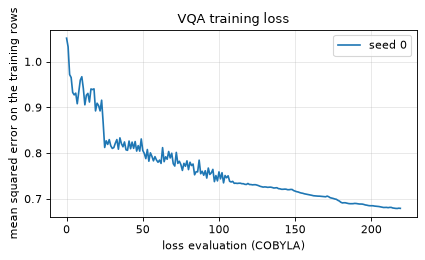

VQA confusion matrix (rows: true, columns: predicted):
 [[62  3]
 [24 11]]
(40 s)


In [16]:
VQA_BW_GRID = [0.25, 0.5, 1.0]                                        # CHOICE
def tune_vqa(seed):
    tr, _ = make_split(seed)
    a, b = train_test_split(tr, train_size=0.7, stratify=y_all[tr], random_state=seed)
    a, b = stratified_subset(a, N_TUNE_VQA, seed), stratified_subset(b, N_TUNE_VAL, seed)           # validation rows are never test rows
    Za, Zb, _ = prep_q(a, b); rows = []
    for bw in VQA_BW_GRID:
        clf = make_vqa(seed, maxiter=TUNE_ITERS, bw=bw).fit(Za, y_all[a]); rows.append(dict(bw=bw, val_acc=100 * accuracy_score(y_all[b], clf.predict(Zb)), train_loss=clf.hist[-1]))
    return pd.DataFrame(rows)
t0 = time.time(); TUNE_V = {}
for s in SEEDS_NN:
    TUNE_V[s] = tune_vqa(s); display(TUNE_V[s].round(3))
print(f"VQA angle scale tuned on validation rows ({time.time() - t0:.0f} s)")

VQA_HIST = {}
def run_vqa(seed):
    tr, te = make_split(seed); sub = stratified_subset(tr, N_TRAIN_VQA, seed); te_s = stratified_subset(te, N_TEST_QML, seed)
    Ztr, Zte, names = prep_q(sub, te_s); bw = float(TUNE_V[seed].sort_values(["val_acc", "bw"], ascending=[False, True]).iloc[0].bw); clf = make_vqa(seed, bw=bw)
    assert dict(transpile(clf.circuit, basis_gates=BASIS, optimization_level=0).count_ops()) == dict(DRAWN["vqa"].count_ops())   # same circuit as drawn
    _, wf, cf, mf = measure(lambda: clf.fit(Ztr, y_all[sub])); p, wp, cp, mp = measure(lambda: clf.predict(Zte))
    log(model="VQA", inputs=f"{N_QUBITS} angles", seed=seed, n_train=len(sub), n_test=len(te_s), t_fit=wf, cpu_fit=cf, mem_fit=mf, t_pred=wp, iters=len(clf.hist), bw=bw, **metrics(y_all[te_s], p))
    cl = classical_on(Ztr, y_all[sub], Zte, seed)
    for name, r in cl.items():
        log(model=name, inputs=f"{N_QUBITS} angles (same rows as VQA)", seed=seed, n_train=len(sub), n_test=len(te_s), t_fit=r["t_fit"], cpu_fit=r["cpu_fit"], mem_fit=r["mem_fit"], t_pred=r["t_pred"], **metrics(y_all[te_s], r["pred"]))
    VQA_HIST[seed] = clf.hist
    if seed == SEEDS_NN[0]:
        MODEL_STORE["vqa"] = dict(model=clf, Ztr=Ztr, ytr=y_all[sub], Zte=Zte, yte=y_all[te_s], bw=bw)
    return p

t0 = time.time()
for s in SEEDS_NN:
    run_vqa(s); r = [x for x in RES if x["model"] == "VQA" and x["seed"] == s][0]
    print(f"seed {s}: VQA n_train={r['n_train']} n_test={r['n_test']}  acc {r['acc']:.2f} %  F1 {r['f1']:.2f}  loss evaluations {r['iters']}  fit {r['t_fit']:.0f} s wall / {r['cpu_fit']:.0f} s CPU, peak extra memory {r['mem_fit']:.0f} MB, predict {r['t_pred']:.1f} s", flush=True)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for s, h in VQA_HIST.items(): ax.plot(h, label=f"seed {s}")
ax.set_xlabel("loss evaluation (COBYLA)"); ax.set_ylabel("mean squared error on the training rows"); ax.set_title("VQA training loss"); ax.legend(); plt.tight_layout(); plt.show()
v_ = MODEL_STORE["vqa"]; print("VQA confusion matrix (rows: true, columns: predicted):\n", confusion_matrix(v_["yte"], v_["model"].predict(v_["Zte"]))); print(f"({time.time() - t0:.0f} s)")

## 7. QCNN: quantum convolutional neural network

The QCNN follows the Qiskit tutorial built on Cong et al.: angle encoding, then three convolution + pooling stages that
halve the number of active qubits (8 -> 4 -> 2 -> 1) with `O(log N)` = 63 trainable rotation angles in total, and the expectation
value of `Z` on the last qubit as the output in [-1, 1] (positive means "Alzheimer's"). It is trained with COBYLA on the
squared error with targets -1 / +1.

seed 0: QCNN n_train=100 n_test=100  acc 67.00 %  F1 60.24  loss evaluations 300  fit 106 s wall / 50 s CPU, peak extra memory 99 MB, predict 0.2 s


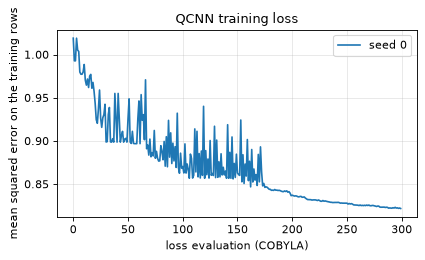

QCNN confusion matrix (rows: true, columns: predicted):
 [[42 23]
 [10 25]]
(113 s)


In [17]:
QCNN_HIST = {}
def run_qcnn(seed):
    tr, te = make_split(seed); sub = stratified_subset(tr, N_TRAIN_QCNN, seed); te_s = stratified_subset(te, N_TEST_QML, seed)
    Ztr, Zte, names = prep_q(sub, te_s); clf = make_qcnn(seed)
    assert dict(transpile(clf.circuit, basis_gates=BASIS, optimization_level=0).count_ops()) == dict(DRAWN["qcnn"].count_ops())   # same circuit as drawn
    _, wf, cf, mf = measure(lambda: clf.fit(Ztr, y_all[sub])); p, wp, cp, mp = measure(lambda: clf.predict(Zte))
    log(model="QCNN", inputs=f"{N_QUBITS} angles", seed=seed, n_train=len(sub), n_test=len(te_s), t_fit=wf, cpu_fit=cf, mem_fit=mf, t_pred=wp, iters=len(clf.hist), **metrics(y_all[te_s], p))
    cl = classical_on(Ztr, y_all[sub], Zte, seed)
    for name, r in cl.items():
        log(model=name, inputs=f"{N_QUBITS} angles (same rows as QCNN)", seed=seed, n_train=len(sub), n_test=len(te_s), t_fit=r["t_fit"], cpu_fit=r["cpu_fit"], mem_fit=r["mem_fit"], t_pred=r["t_pred"], **metrics(y_all[te_s], r["pred"]))
    QCNN_HIST[seed] = clf.hist
    if seed == SEEDS_NN[0]:
        MODEL_STORE["qcnn"] = dict(model=clf, Ztr=Ztr, ytr=y_all[sub], Zte=Zte, yte=y_all[te_s], bw=1.0)
    return p

t0 = time.time()
for s in SEEDS_NN:
    run_qcnn(s); r = [x for x in RES if x["model"] == "QCNN" and x["seed"] == s][0]
    print(f"seed {s}: QCNN n_train={r['n_train']} n_test={r['n_test']}  acc {r['acc']:.2f} %  F1 {r['f1']:.2f}  loss evaluations {r['iters']}  fit {r['t_fit']:.0f} s wall / {r['cpu_fit']:.0f} s CPU, peak extra memory {r['mem_fit']:.0f} MB, predict {r['t_pred']:.1f} s", flush=True)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for s, h in QCNN_HIST.items(): ax.plot(h, label=f"seed {s}")
ax.set_xlabel("loss evaluation (COBYLA)"); ax.set_ylabel("mean squared error on the training rows"); ax.set_title("QCNN training loss"); ax.legend(); plt.tight_layout(); plt.show()
c_ = MODEL_STORE["qcnn"]; print("QCNN confusion matrix (rows: true, columns: predicted):\n", confusion_matrix(c_["yte"], c_["model"].predict(c_["Zte"]))); print(f"({time.time() - t0:.0f} s)")

## 8. Quantum versus classical, model by model (claims C4, C5, C6)

All rows come from the same 90 % / 10 % split family. Each quantum model sits next to the classical models that were trained on
*exactly the same rows and the same 8 angles* (blocks of the table share `n_train`). Mean +- std over the seeds is shown when more
than one seed was run.

n_train     acc  \
family model        inputs                                                 
QSVM   QSVM         8 angles                                 300  82.326   
       SVM          8 angles (same rows as QSVM)             300  82.791   
       MLP          8 angles (same rows as QSVM)             300  80.465   
       RandomForest 8 angles (same rows as QSVM)             300  89.767   
       SVM          all 32 features (same rows as QSVM)      300  82.326   
VQA    VQA          8 angles                                 100  73.000   
       SVM          8 angles (same rows as VQA)              100  71.000   
       MLP          8 angles (same rows as VQA)              100  71.000   
       RandomForest 8 angles (same rows as VQA)              100  85.000   
QCNN   QCNN         8 angles                                 100  67.000   
       SVM          8 angles (same rows as QCNN)             100  71.000   
       MLP          8 angles (same rows as QCNN)             100  71.000   
       RandomForest 8 angles (same rows as QCNN)             100  85.000   

                                                         acc_std      f1  \
family model        inputs                                                 
QSVM   QSVM         8 angles                                 NaN  74.324   
       SVM          8 angles (same rows as QSVM)             NaN  72.993   
       MLP          8 angles (same rows as QSVM)             NaN  72.727   
       RandomForest 8 angles (same rows as QSVM)             NaN  85.135   
       SVM          all 32 features (same rows as QSVM)      NaN  72.059   
VQA    VQA          8 angles                                 NaN  44.898   
       SVM          8 angles (same rows as VQA)              NaN  52.459   
       MLP          8 angles (same rows as VQA)              NaN  57.971   
       RandomForest 8 angles (same rows as VQA)              NaN  76.190   
QCNN   QCNN         8 angles                                 NaN  60.241   
       SVM          8 angles (same rows as QCNN)             NaN  52.459   
       MLP          8 angles (same rows as QCNN)             NaN  57.971   
       RandomForest 8 angles (same rows as QCNN)             NaN  76.190   

                                                         fit_wall_s  \
family model        inputs                                            
QSVM   QSVM         8 angles                                  5.715   
       SVM          8 angles (same rows as QSVM)              0.008   
       MLP          8 angles (same rows as QSVM)              3.629   
       RandomForest 8 angles (same rows as QSVM)              0.960   
       SVM          all 32 features (same rows as QSVM)       0.013   
VQA    VQA          8 angles                                 32.768   
       SVM          8 angles (same rows as VQA)               0.005   
       MLP          8 angles (same rows as VQA)               1.713   
       RandomForest 8 angles (same rows as VQA)               2.012   
QCNN   QCNN         8 angles                                105.774   
       SVM          8 angles (same rows as QCNN)              0.004   
       MLP          8 angles (same rows as QCNN)              1.880   
       RandomForest 8 angles (same rows as QCNN)              1.449   

                                                         fit_cpu_s  peak_MB  \
family model        inputs                                                    
QSVM   QSVM         8 angles                                 4.516    3.082   
       SVM          8 angles (same rows as QSVM)             0.016    0.031   
       MLP          8 angles (same rows as QSVM)             1.953    0.812   
       RandomForest 8 angles (same rows as QSVM)             0.875    2.148   
       SVM          all 32 features (same rows as QSVM)      0.016    0.273   
VQA    VQA          8 angles                                15.859    0.109   
       SVM          8 angles (same rows as VQA)              0.000    0.020  

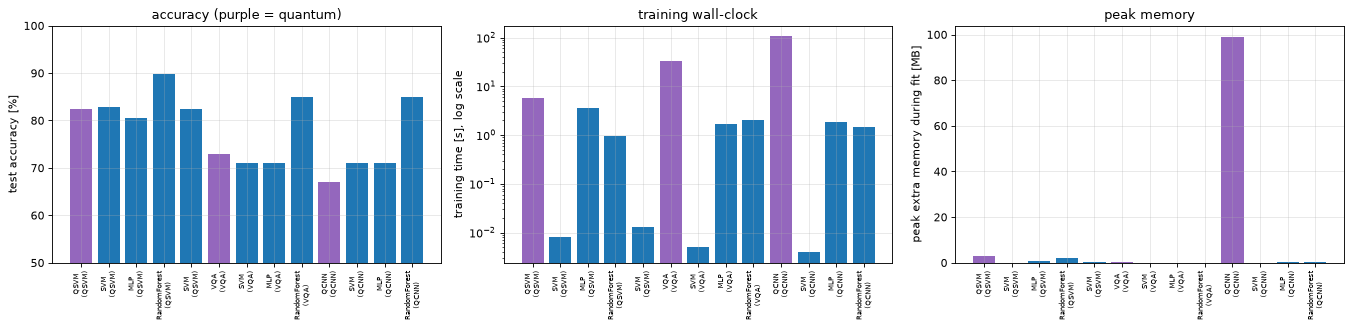

In [18]:
R = pd.DataFrame(RES)
R["family"] = R.inputs.str.extract(r"same rows as (\w+)")[0].fillna(R.model.where(R.model.isin(["QSVM", "VQA", "QCNN"])))
g = R.groupby(["family", "model", "inputs"], sort=False).agg(n_train=("n_train", "first"), acc=("acc", "mean"), acc_std=("acc", "std"), f1=("f1", "mean"),
                                                            fit_wall_s=("t_fit", "mean"), fit_cpu_s=("cpu_fit", "mean"), peak_MB=("mem_fit", "mean"), predict_s=("t_pred", "mean")).round(3)
display(g)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
lab = [f"{m}\n({f})" for (f, m, i) in g.index]
ax[0].bar(range(len(g)), g.acc, yerr=g.acc_std.fillna(0), color=["tab:purple" if m in ("QSVM", "VQA", "QCNN") else "tab:blue" for (f, m, i) in g.index]); ax[0].set_ylabel("test accuracy [%]"); ax[0].set_ylim(50, 100)
ax[1].bar(range(len(g)), g.fit_wall_s, color=["tab:purple" if m in ("QSVM", "VQA", "QCNN") else "tab:blue" for (f, m, i) in g.index]); ax[1].set_yscale("log"); ax[1].set_ylabel("training time [s], log scale")
ax[2].bar(range(len(g)), g.peak_MB, color=["tab:purple" if m in ("QSVM", "VQA", "QCNN") else "tab:blue" for (f, m, i) in g.index]); ax[2].set_ylabel("peak extra memory during fit [MB]")
for a, t in zip(ax, ["accuracy (purple = quantum)", "training wall-clock", "peak memory"]): a.set_xticks(range(len(g))); a.set_xticklabels(lab, rotation=90, fontsize=6); a.set_title(t)
plt.tight_layout(); plt.show()

In [19]:
# Claim C6: the poster's cost ratio. The SVM of the poster is trained on all 32 features; the QSVM on the same number of rows.
q = R[R.model == "QSVM"]; s32 = R[(R.model == "SVM") & R.inputs.str.contains("32")]; s8 = R[(R.model == "SVM") & R.inputs.str.contains("QSVM")]
n_q = int(q.n_train.iloc[0])
ratio_cpu = q.cpu_fit.mean() / max(s32.cpu_fit.mean(), s32.t_fit.mean()); ratio_wall = q.t_fit.mean() / s32.t_fit.mean(); ratio8 = q.t_fit.mean() / s8.t_fit.mean()
print(f"training rows: {n_q} (the full 90 % split has {int(0.9 * len(y_all))})")
print(f"SVM  (32 features): {s32.cpu_fit.mean():.3f} s CPU (clock resolution 0.016 s), {s32.t_fit.mean():.3f} s wall      [poster: {PAPER['svm_cpu_s']} s CPU]")
print(f"SVM  (8 angles)   : {s8.cpu_fit.mean():.3f} s CPU, {s8.t_fit.mean():.3f} s wall")
print(f"QSVM (8 qubits)   : {q.cpu_fit.mean():.1f} s CPU, {q.t_fit.mean():.1f} s wall, peak extra memory {q.mem_fit.mean():.0f} MB   [poster: {PAPER['qsvm_cpu_s']} s]")
print(f"QSVM / SVM(32 features): {ratio_cpu:,.0f}x CPU time, {ratio_wall:,.0f}x wall-clock; QSVM / SVM(8 angles): {ratio8:,.0f}x   [poster: over 4,000x]")
if n_q < int(0.9 * len(y_all)):
    n_full = int(0.9 * len(y_all)); est = q.t_fit.mean() * (n_full / n_q) ** 2
    print(f"FAST_MODE trains on {n_q} rows only; the kernel matrix grows with n^2, so at n = {n_full} the QSVM fit would take about {est:.0f} s (extrapolation, not a measurement).")

training rows: 300 (the full 90 % split has 1934)
SVM  (32 features): 0.016 s CPU (clock resolution 0.016 s), 0.013 s wall      [poster: 0.03 s CPU]
SVM  (8 angles)   : 0.016 s CPU, 0.010 s wall
QSVM (8 qubits)   : 4.5 s CPU, 5.7 s wall, peak extra memory 3 MB   [poster: 132.07 s]
QSVM / SVM(32 features): 289x CPU time, 449x wall-clock; QSVM / SVM(8 angles): 564x   [poster: over 4,000x]
FAST_MODE trains on 300 rows only; the kernel matrix grows with n^2, so at n = 1934 the QSVM fit would take about 238 s (extrapolation, not a measurement).


## 9. What does exact simulation cost? (claim C7)

The poster says simulating quantum algorithms on a classical computer needs a large memory and a lot of CPU time. The cost of
an exact state-vector simulation is easy to state: one state needs `2^n` complex numbers (16 bytes each). A quantum kernel over
`N` patients needs all `N` states, so memory grows like `N x 2^n` and the number of inner products like `N^2`. The next cell
measures the time and peak memory of simulating the ZZ feature-map circuit for increasing qubit numbers and then extrapolates what
a kernel over the 1,934 training patients would need.

,qubits,amplitudes,state_MB_theory,time_per_state_s,peak_extra_MB_measured,kernel_states_GB_for_1934_patients,extrapolated_state_time_for_1934_patients_s
0,4,16,0.0002,0.0052,0.0312,0.0005,10.0522
1,8,256,0.0039,0.0108,0.0039,0.0074,20.9367
2,12,4096,0.0625,0.0235,0.2031,0.1180,45.4575
3,14,16384,0.2500,0.1507,1.2734,0.4722,291.4172
4,16,65536,1.0000,2.7462,4.0742,1.8887,5311.0903


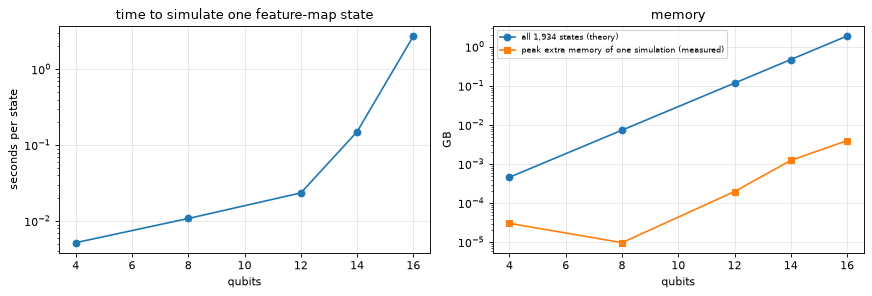

A 32-qubit circuit (one qubit per feature of the table) would need 64 GB for a single state and 121 TB for the 1,934 training states.


In [20]:
rows = []
for n in SCALING_QUBITS:
    fm = zz_feature_map(n, reps=2, entanglement="linear"); x = np.random.default_rng(n).uniform(0, np.pi, n)
    sv, w, c, m = measure(lambda: Statevector(fm.assign_parameters(x)))
    rows.append(dict(qubits=n, amplitudes=2 ** n, state_MB_theory=2 ** n * 16 / 2**20, time_per_state_s=w, peak_extra_MB_measured=m))
SC = pd.DataFrame(rows); N_TR = int(0.9 * len(y_all))
SC["kernel_states_GB_for_1934_patients"] = SC.state_MB_theory * N_TR / 1024
SC["extrapolated_state_time_for_1934_patients_s"] = SC.time_per_state_s * N_TR
display(SC.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(SC.qubits, SC.time_per_state_s, "-o"); ax[0].set_xlabel("qubits"); ax[0].set_ylabel("seconds per state"); ax[0].set_title("time to simulate one feature-map state")
ax[1].semilogy(SC.qubits, SC.state_MB_theory * N_TR / 1024, "-o", label="all 1,934 states (theory)"); ax[1].semilogy(SC.qubits, SC.peak_extra_MB_measured.clip(lower=0.01) / 1024, "-s", label="peak extra memory of one simulation (measured)")
ax[1].set_xlabel("qubits"); ax[1].set_ylabel("GB"); ax[1].set_title("memory"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("A 32-qubit circuit (one qubit per feature of the table) would need", f"{2 ** 32 * 16 / 2**30:.0f} GB for a single state and {2 ** 32 * 16 * N_TR / 2**40:,.0f} TB for the 1,934 training states.")

## 10. Security implications: from arguments to experiments (extension, not in the poster)

The poster's security part is argument only. Two of its statements can be tested on the models trained above, so the notebook
adds two small experiments. They are **additions to the poster**, labelled as such in the final table.

**10.1 Inherited vulnerability: black-box adversarial examples (claim C8).** The poster says QML inherits the crafted-adversarial-example
weakness of classical ML and that this should be easier when the model is less accurate. The attack here is deliberately simple
and model-agnostic: it only needs the model's score, not its gradient or internals. For each correctly classified test patient it
tries `K` random sign perturbations of size `eps` per angle (an L-infinity ball in the [0, pi] angle space), keeps the one that moves the
score most towards the wrong class and repeats this `ATTACK_ROUNDS` times, always staying inside the ball around the original patient. The
same attack and the same patients are used for every model; `eps` is a fraction of the angle range. As a control, a single random
perturbation of the same size is tried as well. Each model attacks in its own angle space (the quantum models and the classical
RBF-SVM/MLP trained on the QSVM rows with its preprocessing); for the QSVM the circuit angles are `bw * angles`, so the same
`eps` is a smaller change of the circuit input.

QSVM: done (18 s)


SVM (rbf): done (18 s)


MLP: done (18 s)

VQA: done (23 s)


QCNN: done (32 s)


,model,eps_pct_of_range,clean_acc,robust_acc_search,acc_after_random_noise,attack_success_on_correct
0,QSVM,5.0,80.0,76.7,83.3,4.2
1,QSVM,10.0,80.0,60.0,86.7,25.0
2,QSVM,20.0,80.0,43.3,80.0,45.8
3,SVM (rbf),5.0,80.0,80.0,83.3,0.0
4,SVM (rbf),10.0,80.0,63.3,86.7,20.8
5,SVM (rbf),20.0,80.0,46.7,86.7,41.7
6,MLP,5.0,76.7,63.3,80.0,17.4
7,MLP,10.0,76.7,60.0,83.3,21.7
8,MLP,20.0,76.7,40.0,83.3,47.8
9,VQA,5.0,76.7,73.3,76.7,4.3


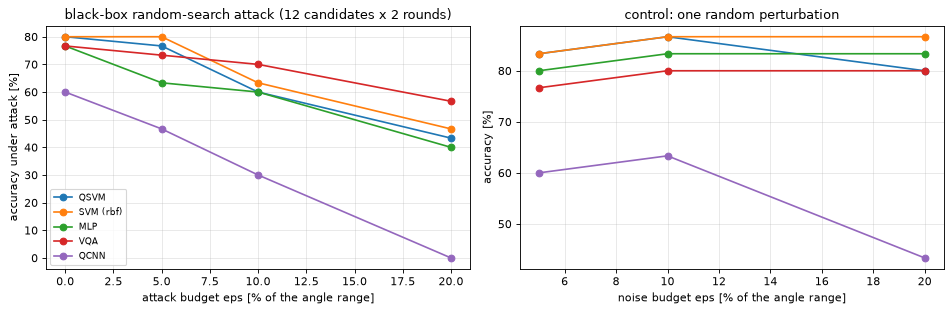

(34 s, 30 attacked patients)


In [21]:
def fit_prep(tr, k=N_QUBITS):
    sel = SelectKBest(f_classif, k=k).fit(X_all[tr], y_all[tr])
    ss = StandardScaler().fit(sel.transform(X_all[tr])); mm = MinMaxScaler((0, np.pi)).fit(ss.transform(sel.transform(X_all[tr])))
    return lambda idx: np.clip(mm.transform(ss.transform(sel.transform(X_all[idx]))), 0, np.pi)

def score_fns():
    # continuous score per model: positive = predicted class 1 (Alzheimer's); every function takes angles in [0, pi]
    out = {}
    q = MODEL_STORE["qsvm"]; bw, m = q["bw"], q["model"]; fm = make_qsvm_fm()
    S_tr = aer_states(fm, bw * q["Ztr"]); sv, dual, b0 = m.support_, m.dual_coef_[0], m.intercept_[0]
    def qsvm_score(Z):
        S = aer_states(fm, bw * Z); return (np.abs(S.conj() @ S_tr[sv].T) ** 2) @ dual + b0       # kernel to the support vectors only
    assert np.allclose(qsvm_score(q["Zte"][:15]), m.decision_function(bw * q["Zte"][:15]), atol=1e-6)       # identical to QSVC.decision_function
    out["QSVM"] = qsvm_score
    out["SVM (rbf)"] = MODEL_STORE["cl8"]["SVM"].decision_function
    out["MLP"] = lambda Z: MODEL_STORE["cl8"]["MLP"].predict_proba(Z)[:, 1] - 0.5
    out["VQA"] = MODEL_STORE["vqa"]["model"].decision_function
    out["QCNN"] = MODEL_STORE["qcnn"]["model"].decision_function
    return out

def attack(score, Z, y, eps, K, rounds, rng):
    # black-box L-inf random-search attack; returns the margin (positive = still correct) before and after, and the adversarial points
    sgn = 2 * y - 1; n, d = Z.shape; cur = Z.copy(); m0 = sgn * score(Z); best = m0.copy()
    lo, hi = np.maximum(Z - eps, 0.0), np.minimum(Z + eps, np.pi)
    for _ in range(rounds):
        cand = np.clip(cur[:, None, :] + eps * rng.choice([-1.0, 1.0], size=(n, K, d)), lo[:, None, :], hi[:, None, :])
        m = sgn[:, None] * score(cand.reshape(-1, d)).reshape(n, K); j = m.argmin(1); mj = m[np.arange(n), j]; better = mj < best
        cur[better] = cand[np.arange(n), j][better]; best = np.where(better, mj, best)
    return m0, best, cur

t0 = time.time()
SC_FN = score_fns()
te_att = stratified_subset(make_split(0)[1], ATTACK_N, 0)                 # the same patients for every model
assert SEEDS_QML[0] == 0 and SEEDS_NN[0] == 0                                               # the stored models are the seed-0 models
tr_f, _ = make_split(0)
F_Q = fit_prep(MODEL_STORE["qsvm"]["sub"])                                         # preprocessing of the QSVM / classical-8 rows
F_V = fit_prep(stratified_subset(tr_f, N_TRAIN_VQA, 0)); F_C = fit_prep(stratified_subset(tr_f, N_TRAIN_QCNN, 0))
FEATS = {"QSVM": F_Q, "SVM (rbf)": F_Q, "MLP": F_Q, "VQA": F_V, "QCNN": F_C}
y_att = y_all[te_att]; rows = []; ADV = {}
for name, fn in SC_FN.items():
    Z = FEATS[name](te_att); clean_ok = (2 * y_att - 1) * fn(Z) > 0
    for ef in EPS_FRACS:
        eps = ef * np.pi
        m0, m1, adv = attack(fn, Z, y_att, eps, ATTACK_K, ATTACK_ROUNDS, np.random.default_rng(SEED))
        Zr = np.clip(Z + eps * np.random.default_rng(SEED).choice([-1.0, 1.0], size=Z.shape), np.maximum(Z - eps, 0.0), np.minimum(Z + eps, np.pi))   # control: ONE random sign perturbation, always applied
        mr = (2 * y_att - 1) * fn(Zr)
        rows.append(dict(model=name, eps_pct_of_range=100 * ef, clean_acc=100 * clean_ok.mean(), robust_acc_search=100 * (m1 > 0).mean(), acc_after_random_noise=100 * (mr > 0).mean(),
                         attack_success_on_correct=100 * ((m0 > 0) & (m1 <= 0)).sum() / max((m0 > 0).sum(), 1)))
        ADV[(name, ef)] = (Z, adv)
    print(f"{name}: done ({time.time() - t0:.0f} s)", flush=True)
ATT = pd.DataFrame(rows); display(ATT.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, g in ATT.groupby("model", sort=False):
    ax[0].plot([0] + list(g.eps_pct_of_range), [g.clean_acc.iloc[0]] + list(g.robust_acc_search), "-o", label=name)
    ax[1].plot(g.eps_pct_of_range, g.acc_after_random_noise, "-o", label=name)
ax[0].set_xlabel("attack budget eps [% of the angle range]"); ax[0].set_ylabel("accuracy under attack [%]"); ax[0].set_title(f"black-box random-search attack ({ATTACK_K} candidates x {ATTACK_ROUNDS} rounds)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("noise budget eps [% of the angle range]"); ax[1].set_ylabel("accuracy [%]"); ax[1].set_title("control: one random perturbation"); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s, {len(te_att)} attacked patients)")

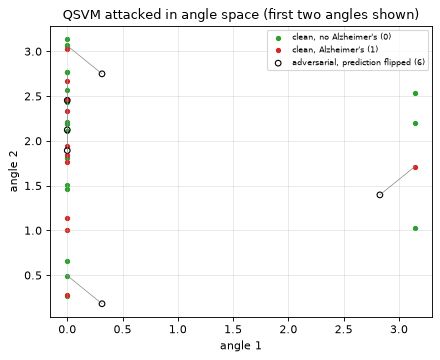

In [22]:
# Where is the decision boundary crossed?  First two angles of the QSVM space: the attacked patients, the clean point and the adversarial point (eps = 10 % of the range).
Z, adv = ADV[("QSVM", 0.10)]; q_ = MODEL_STORE["qsvm"]; mfun = SC_FN["QSVM"]
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ok = (2 * y_att - 1) * mfun(Z) > 0; flipped = ok & ((2 * y_att - 1) * mfun(adv) <= 0)
for c in (0, 1): ax.scatter(Z[y_att == c, 0], Z[y_att == c, 1], s=14, color=COL[c], label=f"clean, {LAB[c]}")
ax.scatter(adv[flipped, 0], adv[flipped, 1], s=26, facecolors="none", edgecolors="k", label=f"adversarial, prediction flipped ({flipped.sum()})")
for i in np.where(flipped)[0]: ax.plot([Z[i, 0], adv[i, 0]], [Z[i, 1], adv[i, 1]], color="gray", lw=0.6)
ax.set_xlabel("angle 1"); ax.set_ylabel("angle 2"); ax.set_title("QSVM attacked in angle space (first two angles shown)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

**Reading the attack results (FAST_MODE: 30 attacked patients, so one patient is 3.3 accuracy points and the standard error of every accuracy is about 7 to 9
points).** Every model loses accuracy under the targeted black-box search while one random perturbation of the same size leaves the accuracy unchanged or
slightly higher up to eps = 10 % (only the QCNN also drops at 20 %), so the loss comes from the search, not from noise: the QSVM goes from 80 % to 60 % at eps = 10 % of the angle range, the classical RBF-SVM from 80 % to 63 %, the MLP from 77 % to 60 %,
the VQA from 77 % to 70 % and the QCNN from 60 % to 30 %. The QSVM is not more robust than the classical SVM in absolute angle units, although its circuit
sees only `bw` times the perturbation (bw = 1/32 here). The ranking by fragility does not follow the ranking by clean accuracy (the VQA is the most robust model although it is not the most accurate),
which is why the correlation test in section 11 does not support the poster's inference with this data; the QCNN, the least accurate model, is the most fragile.

**10.2 Quantum noise as an attack vector (claim C9).** The poster mentions exploiting quantum noise to degrade a quantum model.
The trained VQA is evaluated again with a depolarising error after every two-qubit gate (probability `p`, and `p/10` after one-qubit
gates; CHOICE) on the Aer simulator, using the weights learned on the ideal simulator (exact density-matrix simulation of the transpiled circuit). An attacker who can raise the error rate
of the hardware (or who shares it) therefore moves the model along this curve. Only the VQA is swept; the QSVM and QCNN could be treated the same way (exercise 5).

noise-free density-matrix expectation == ideal expectation (max diff 2.3e-15)  ->  OK


,two_qubit_error_pct,accuracy,auc,mean_abs_output,output_shrinkage
0,0.0,73.0,69.407,0.289,1.000
1,1.0,74.0,69.582,0.276,0.953
2,5.0,72.0,69.055,0.229,0.791
3,10.0,72.0,68.703,0.181,0.628


VQA transpiled to rz/sx/x/cx: 14 CNOTs, depth 25; rows evaluated: 100; ideal accuracy on the same rows: 73.0 %


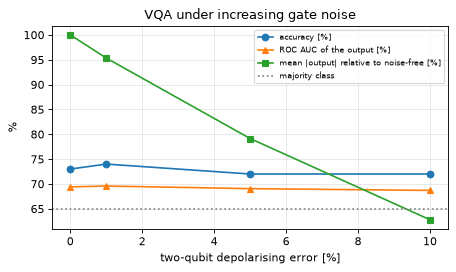

(498 s)


In [23]:
NOISE_BASIS = ["rz", "sx", "x", "cx"]
def noisy_vqa_expectation(clf, Z, p2):
    # exact mean <Z_i> of the trained VQA circuit under depolarising noise (density-matrix Aer simulation of the transpiled circuit, no shot noise)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"]); nm.add_all_qubit_quantum_error(depolarizing_error(p2 / 10, 1), ["sx", "x"])   # CHOICE: error model
    f = BatchedExpval(clf.circuit, clf.input_params, clf.weight_params, VQA_OBS, simulator=AerSimulator(noise_model=nm, method="density_matrix"), basis_gates=NOISE_BASIS)
    return f(clf.bw * np.asarray(Z), clf.weights), f.qc

t0 = time.time(); v_ = MODEL_STORE["vqa"]; Zn, yn = v_["Zte"][:NOISE_N_TEST], v_["yte"][:NOISE_N_TEST]
ideal = v_["model"].decision_function(Zn)
e0, tq = noisy_vqa_expectation(v_["model"], Zn, 0.0); assert np.allclose(e0, ideal, atol=1e-6)         # the transpiled density-matrix path with no noise equals the ideal circuit
print("noise-free density-matrix expectation == ideal expectation (max diff %.1e)  ->  OK" % np.abs(e0 - ideal).max())
rows = []
for p2 in NOISE_LEVELS:
    e, _ = noisy_vqa_expectation(v_["model"], Zn, p2)
    rows.append(dict(two_qubit_error_pct=100 * p2, accuracy=100 * accuracy_score(yn, (e > 0).astype(int)), auc=100 * roc_auc_score(yn, e), mean_abs_output=np.abs(e).mean(), output_shrinkage=np.abs(e).mean() / max(np.abs(ideal).mean(), 1e-12)))
NZ = pd.DataFrame(rows); display(NZ.round(3))
print(f"VQA transpiled to rz/sx/x/cx: {tq.count_ops().get('cx', 0)} CNOTs, depth {tq.depth()}; rows evaluated: {len(yn)}; ideal accuracy on the same rows: {100 * accuracy_score(yn, (ideal > 0).astype(int)):.1f} %")
fig, ax = plt.subplots(figsize=(5.8, 3.5)); ax.plot(NZ.two_qubit_error_pct, NZ.accuracy, "-o", label="accuracy [%]"); ax.plot(NZ.two_qubit_error_pct, NZ.auc, "-^", label="ROC AUC of the output [%]"); ax.plot(NZ.two_qubit_error_pct, 100 * NZ.output_shrinkage, "-s", label="mean |output| relative to noise-free [%]")
ax.axhline(100 * (1 - yn.mean()), color="gray", ls=":", label="majority class"); ax.set_xlabel("two-qubit depolarising error [%]"); ax.set_ylabel("%"); ax.set_title("VQA under increasing gate noise"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s)")

**Reading the noise results.** With the 14-CNOT VQA circuit, a two-qubit error of up to 10 % changes the accuracy by about one point (73 % to 72 %) and the ROC AUC by less than one point,
but the mean output magnitude falls to about 63 % of the noise-free value: depolarising noise first pulls the outputs towards zero (the maximally mixed state) and erodes the model's confidence
before it flips decisions. With a model whose margins are this small (it mostly separates the classes by a few clinical scores) and a circuit this shallow, the poster's "exploit noise to degrade the model"
scenario is only visible through the shrinking margin; a deeper circuit, a larger error rate or a model with smaller margins would show flipped decisions earlier.

## 11. Side-by-side comparison with the poster

Every checkable statement of the poster, the notebook's number and a verdict. The tolerance for numeric accuracy claims is 2
accuracy points (`TOL`). Timings are machine-dependent; for those the verdict compares orders of magnitude and ratios.

In [24]:
def verdict(nb, paper, tol=TOL, higher_is_better=True):
    if abs(nb - paper) <= tol: return "reproduced"
    return ("not reached" if nb < paper else "exceeded") + f" (gap {nb - paper:+.1f})"

R = pd.DataFrame(RES); rows = []
acc = lambda m, f: LC_m[(m, f)]
for m in ["SVM (rbf, C=1)", "MLP (64,32)"]:
    rows.append(("C1", f"{m}: accuracy with 10 % training data [%]", PAPER["acc_10"], acc(m, 0.1), verdict(acc(m, 0.1), PAPER["acc_10"])))
    rows.append(("C1/C2", f"{m}: accuracy with 90 % training data [%]", PAPER["acc_90"], acc(m, 0.9), verdict(acc(m, 0.9), PAPER["acc_90"])))
rows.append(("C1", "growth 10 % -> 90 % (SVM, points)", PAPER["acc_90"] - PAPER["acc_10"], acc("SVM (rbf, C=1)", 0.9) - acc("SVM (rbf, C=1)", 0.1), verdict(acc("SVM (rbf, C=1)", 0.9) - acc("SVM (rbf, C=1)", 0.1), PAPER["acc_90"] - PAPER["acc_10"])))
rows.append(("C2", "best SVM/MLP accuracy at 90 % (incl. CV-tuned SVM) [%]", PAPER["best"], BEST_SVM_MLP, verdict(BEST_SVM_MLP, PAPER["best"])))
rk = RANK.loc["MemoryComplaints"]
rows.append(("C3", "MemoryComplaints is the most influential feature (best rank over four measures)", "rank 1", f"ranks {rk.to_dict()}", "reproduced" if (rk == 1).all() else ("not reached (top-3, not first)" if rk.min() <= 3 and (rk == 1).sum() == 0 else "partly: rank 1 in %d of 4 measures" % (rk == 1).sum())))

def mean_of(model, key, inputs_contains=None):
    d = R[R.model == model]
    if inputs_contains: d = d[d.inputs.str.contains(inputs_contains, regex=False)]
    return d[key].mean()
q_acc = mean_of("QSVM", "acc"); sv_acc = R[(R.model == "SVM") & R.inputs.str.contains("QSVM")].acc.mean(); sv32_acc = R[(R.model == "SVM") & R.inputs.str.contains("32")].acc.mean()
rows.append(("C4", "QSVM does not surpass SVM in accuracy (same rows, same 8 angles) [%]", "QSVM <= SVM", f"QSVM {q_acc:.1f} vs SVM {sv_acc:.1f}", "reproduced" if q_acc <= sv_acc + TOL else f"not reached (QSVM is {q_acc - sv_acc:+.1f} points above)"))
rows.append(("C4", "QSVM does not surpass SVM trained on all 32 features [%]", "QSVM <= SVM", f"QSVM {q_acc:.1f} vs SVM(32) {sv32_acc:.1f}", "reproduced" if q_acc <= sv32_acc + TOL else f"not reached (QSVM is {q_acc - sv32_acc:+.1f} points above)"))
v_acc = mean_of("VQA", "acc"); vc_acc = R[R.model.isin(["SVM", "MLP"]) & R.inputs.str.contains("VQA")].acc.max()
rows.append(("C4", "VQA does not surpass the classical SVM/MLP (same rows, better of the two) [%]", "VQA <= classical", f"VQA {v_acc:.1f} vs SVM/MLP {vc_acc:.1f}", "reproduced" if v_acc <= vc_acc + TOL else f"not reached (VQA is {v_acc - vc_acc:+.1f} points above)"))
c_acc = mean_of("QCNN", "acc"); cc_acc = R[(R.model == "SVM") & R.inputs.str.contains("QCNN")].acc.mean()
rows.append(("C5", "QCNN accuracy equals the SVM accuracy (same rows) [%]", "QCNN = SVM", f"QCNN {c_acc:.1f} vs SVM {cc_acc:.1f}", verdict(c_acc, cc_acc)))
s32 = R[(R.model == "SVM") & R.inputs.str.contains("32")]; qr = R[R.model == "QSVM"]; n_q = int(qr.n_train.iloc[0]); n_full = int(0.9 * len(y_all))
svm_t = max(s32.cpu_fit.mean(), s32.t_fit.mean())
rows.append(("C6", "SVM training CPU time [s]", PAPER["svm_cpu_s"], round(svm_t, 3), "machine-dependent: same order of magnitude" if 0.003 <= svm_t <= 0.3 else "machine-dependent"))
qt = qr.cpu_fit.mean() if n_q >= n_full else qr.cpu_fit.mean() * (n_full / n_q) ** 2
rows.append(("C6", "QSVM training CPU time at 90 % of the data [s]" + ("" if n_q >= n_full else " (extrapolated from %d rows)" % n_q), PAPER["qsvm_cpu_s"], round(qt, 1),
             ("same order of magnitude" if 13 <= qt <= 1320 else "differs by > 10x") + ("" if n_q >= n_full else "; cannot be checked at full size in FAST_MODE")))
svm_s = max(s32.cpu_fit.mean(), s32.t_fit.mean())            # CPU time, or wall-clock when the CPU time is below the 15.6 ms clock resolution of Windows
rat = qr.cpu_fit.mean() / svm_s
rows.append(("C6", f"QSVM / SVM CPU-time ratio at {n_q} rows", ">4000", round(rat), "reproduced (ratio > 4000)" if rat > 4000 else ("not reached at %d rows (ratio %.0f)" % (n_q, rat)) + ("; the QSVM cost grows with n^2, so at 1,934 rows the ratio would be about %.0f (extrapolation: cannot be checked in FAST_MODE)" % (rat * (n_full / n_q) ** 2) if n_q < n_full else "")))
rows.append(("C7", "exact simulation needs much more CPU time than the classical model", "qualitative", f"QSVM / SVM CPU time {rat:.0f}x at {n_q} rows", "reproduced" if rat > 20 else "not reached"))
rows.append(("C7", "exact simulation needs a very large memory", "qualitative", f"QSVM fit peak +{qr.mem_fit.mean():.0f} MB vs SVM +{s32.mem_fit.mean():.0f} MB at 8 qubits; state memory doubles per qubit ({SC.state_MB_theory.iloc[-1]:.0f} MB per state at {SC.qubits.iloc[-1]} qubits; time per state {SC.time_per_state_s.iloc[-1] / SC.time_per_state_s.iloc[0]:.0f}x from {SC.qubits.iloc[0]} to {SC.qubits.iloc[-1]} qubits)",
             "not reached at 8 qubits (a few MB); holds only for larger circuits (exponential growth shown above)" if qr.mem_fit.mean() < 200 else "reproduced"))
a10 = ATT[ATT.eps_pct_of_range.round() == 10].set_index("model"); drop = (a10.clean_acc - a10.robust_acc_search)
rows.append(("C8 (extension)", "QML models are vulnerable to adversarial examples like classical models (accuracy drop at eps = 10 % of the range, points)", "qualitative", drop.round(1).to_dict(),
             "reproduced for all quantum models" if all(drop[m] > 0 for m in ["QSVM", "VQA", "QCNN"]) else "not shown for every quantum model"))
rho = pd.Series(a10.clean_acc).corr(drop, method="spearman")
rows.append(("C8 (extension)", "less accurate models are easier to attack (Spearman correlation clean accuracy vs accuracy drop, 5 models)", "negative", round(rho, 2),
             "consistent (rho < -0.5, only 5 models)" if rho < -0.5 else "not supported by this data (rho = %.2f, only 5 models)" % rho))
rows.append(("C9 (extension)", "quantum (gate) noise degrades a quantum model: VQA accuracy / ROC AUC [%] at the highest vs the lowest error level", "degrades", f"accuracy {NZ.accuracy.iloc[-1]:.1f} vs {NZ.accuracy.iloc[0]:.1f}; AUC {NZ.auc.iloc[-1]:.1f} vs {NZ.auc.iloc[0]:.1f}",
             "reproduced" if (NZ.accuracy.iloc[-1] < NZ.accuracy.iloc[0] - TOL or NZ.auc.iloc[-1] < NZ.auc.iloc[0] - TOL) else "not shown at these noise levels"))
CMP = pd.DataFrame(rows, columns=["claim", "statement", "poster", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 250); display(CMP)
print(CMP.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,statement,poster,this notebook,verdict
0,C1,"SVM (rbf, C=1): accuracy with 10 % training data [%]",80.0,78.501292,reproduced
1,C1/C2,"SVM (rbf, C=1): accuracy with 90 % training data [%]",87.0,83.72093,not reached (gap -3.3)
2,C1,"MLP (64,32): accuracy with 10 % training data [%]",80.0,79.173127,reproduced
3,C1/C2,"MLP (64,32): accuracy with 90 % training data [%]",87.0,80.310078,not reached (gap -6.7)
4,C1,"growth 10 % -> 90 % (SVM, points)",7.0,5.219638,reproduced
5,C2,best SVM/MLP accuracy at 90 % (incl. CV-tuned SVM) [%],87.0,85.89,reproduced
6,C3,MemoryComplaints is the most influential feature (best rank over four measures),rank 1,"ranks {'ANOVA F': 3, '|corr|': 3, 'RF impurity': 4, 'SVM permutation': 3}","not reached (top-3, not first)"
7,C4,"QSVM does not surpass SVM in accuracy (same rows, same 8 angles) [%]",QSVM <= SVM,QSVM 82.3 vs SVM 82.6,reproduced
8,C4,QSVM does not surpass SVM trained on all 32 features [%],QSVM <= SVM,QSVM 82.3 vs SVM(32) 82.3,reproduced
9,C4,"VQA does not surpass the classical SVM/MLP (same rows, better of the two) [%]",VQA <= classical,VQA 73.0 vs SVM/MLP 71.0,reproduced


{'reproduced': 9, 'not': 8, 'machine-dependent:': 1, 'same': 1}


**Summary of the verdicts (FAST_MODE numbers; see the table for the exact values).**

* *Reproduced:* accuracy at 10 % training data (78.5 % SVM, 79.2 % MLP against about 80 %); a moderate growth with more data (SVM +5.2 points against +7); the best SVM/MLP-type accuracy (85.9 % for a linear SVM, against 87 %; the leakage-free CV-tuned SVM reaches 84.5 %);
  that QSVM and the VQA do not beat the classical SVM/MLP on the same rows (QSVM 82.3 % against 82.6 %, VQA 73 % against 71 %), and that exact simulation needs far more CPU time than the classical model (a few hundred times at 300 rows).
* *Not reached:* the default SVM and MLP at 90 % training data stay at 83.7 % and 80.3 % (poster 87 %); `MemoryComplaints` is the third most influential feature under three of four measures and the fourth under the fourth (rank 1 is `FunctionalAssessment`);
  the QCNN is four points below the SVM instead of equal; a 4,000-fold cost ratio is not reached at 300 rows (289-fold; the n^2 growth of the kernel puts it above 4,000 at 1,934 rows, which cannot be checked in FAST_MODE); simulation memory is only a few MB at 8 qubits (the exponential growth is shown, not a large footprint).
* *Cannot be checked here:* the poster's absolute CPU times (machine-dependent) and the full-size QSVM time (extrapolated, 188 s against 132 s).
* *Extension (not in the poster):* all models, quantum and classical, are vulnerable to a simple black-box attack; the data do not support "less accurate means easier to attack"; gate noise up to 10 % erodes the VQA's confidence much more than its accuracy.

Overall this is a *partial* reproduction: the qualitative conclusions of the poster (QML does not beat classical ML here, simulation is costly) hold, several of its quantitative values are not matched, and its security statements are arguments that the extension can only partly test.

## 12. Reading the paper critically

* **A two-page poster is not a reproducible study.** It gives no qubit number, feature map, ansatz, optimiser, number of
  training rows for the quantum models, random seed or timing environment. Every quantum number in the table above therefore
  depends on choices the poster does not fix, and the CPU times (0.03 s, 132.07 s) are only meaningful as an order of
  magnitude.
* **"Quantum models did not surpass classical ones" depends on the classical baseline.** Here the classical SVM and MLP on all
  32 features are clearly *worse* than a RandomForest (see the learning curve), and most of the 32 columns carry almost no signal
  (only five clinical scores correlate with the label). Compare the QSVM with the right classical reference (same rows, same
  inputs, and a strong model such as the RandomForest) before drawing a conclusion.
* **The data set looks generated, not clinical.** Most numeric columns are close to uniform over a fixed range, `DoctorInCharge` is one
  constant string, and the diagnosis is almost a function of a few clinical scores (functional assessment, ADL, MMSE, memory complaints,
  behavioural problems). Conclusions about "real-world applications" should be drawn with care.
* **The simulation cost is a property of the simulator, not of quantum computing.** Exact state-vector simulation grows as
  `2^n` in memory and `N^2` in kernel entries; a quantum computer would not pay that price, but it would pay shot noise, gate noise
  and queue time, which the poster does not measure.
* **The security section is an inference.** "Less accurate -> easier to attack" is plausible but not shown by the poster; with five
  models the correlation computed above cannot settle it. The black-box attack used here is weak (random search) and the attacked sets are small (see the sizes printed above); stronger
  white-box attacks, adversarial training and noise-aware defences are what a real study would evaluate.
* **Medical use.** The data are not patient records and none of these models is validated for diagnosis.

## 13. Exercises

1. Change `N_QUBITS` to 4 and 6 (use `N_QUBITS = 4` for a 4-qubit QCNN by editing `make_qcnn_ansatz`) and plot QSVM accuracy against the number
   of qubits. Which features are selected, and does the kernel bandwidth change?
2. Replace the ZZ feature map by `z_feature_map` (no entanglement) and by `pauli_feature_map(paulis=["Z", "YY"])`. Does the entanglement help
   on this data? Compare with the RBF-SVM on the same angles.
3. Train the SVM on all 32 features with 100 random subsets of 300 patients and compare its accuracy and time with the QSVM at 300 rows.
   How many training rows can the QSVM afford with a 60 s budget on your machine?
4. Increase `ATTACK_K` and `ATTACK_ROUNDS`, or implement a gradient-based attack for the SVM (RBF decision function) and the QCNN
   (parameter-shift on the inputs). Which model loses accuracy fastest per unit of `eps`?
5. Add adversarial training: augment the QSVM/SVM training rows with the adversarial points found by the attack and re-measure the robust
   accuracy. Does it cost clean accuracy? Repeat the noise sweep with a noise model taken from an IBM fake backend (`qiskit_ibm_runtime.fake_provider`).